In [1]:
import numpy as np
import pandas as pd
import os
import warnings
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.impute import KNNImputer
from scipy.stats.mstats import winsorize
from sklearn.model_selection import train_test_split
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.preprocessing import StandardScaler

In [2]:
def load_csv(file_path):
    """Loads a CSV file into a DataFrame"""
    try:
        if not os.path.exists(file_path):
            raise FileNotFoundError(f"Error: File '{file_path}' not found!")

        df = pd.read_csv(file_path)

        print(f"✅ CSV file! Shape: {df.shape}")

        return df
    except FileNotFoundError as fnf_error:
        print(fnf_error)
    except pd.errors.EmptyDataError:
        print("Error: The CSV file is empty!")
    except pd.errors.ParserError:
        print("Error: CSV parsing issue. Check the file format.")
    except Exception as e:
        print(f"Unexpected error: {e}")

    return None  

In [25]:
df = pd.read_csv('/kaggle/input/stroke-prediction-dataset/healthcare-dataset-stroke-data.csv')

# Quick peek on data

In [26]:
df.head()

/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: invalid value encountered in greater
  has_large_values = (abs_vals > 1e6).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in less
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in greater
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [27]:
df.columns

Index(['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'stroke'],
      dtype='object')

In [28]:

def get_basic_info(df):
    """Get basic information about the dataset"""
    print(f"🔹 Number of Rows: {df.shape[0]}")
    print(f"🔹 Number of Columns: {df.shape[1]}")
    print(f"🔹 Columns: {df.columns.tolist()}")
    print(f"🔹 Column Data Types: {df.dtypes}")
    print(f"🔹 Missing Values: {df.isnull().sum().sum()}")
    print(f"🔹 Missing Values (Per Column) : {df.isnull().sum()}")
    print(f"🔹 Missing Values (Per Column Percentage) : {(df.isnull().mean() * 100)}")
    print(f"🔹 Unique Values: {df.nunique()}")

In [29]:
get_basic_info(df)

🔹 Number of Rows: 5110
🔹 Number of Columns: 12
🔹 Columns: ['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status', 'stroke']
🔹 Column Data Types: id                     int64
gender                object
age                  float64
hypertension           int64
heart_disease          int64
ever_married          object
work_type             object
Residence_type        object
avg_glucose_level    float64
bmi                  float64
smoking_status        object
stroke                 int64
dtype: object
🔹 Missing Values: 201
🔹 Missing Values (Per Column) : id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64
🔹 Missing Values (Per Column Per

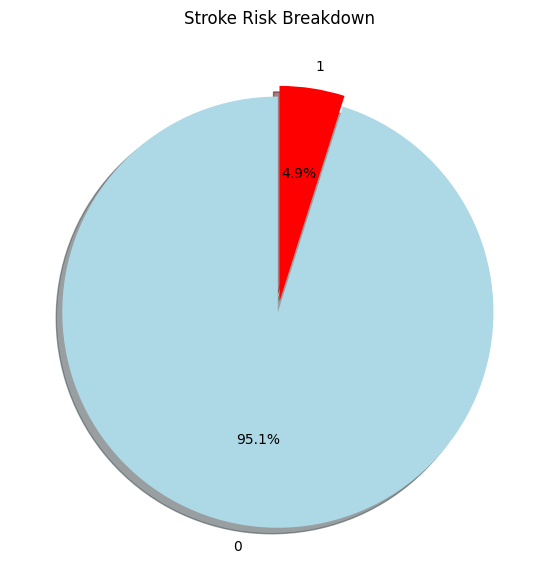

In [30]:
labels = df['stroke'].value_counts(sort=True).index
sizes = df['stroke'].value_counts(sort=True)

colors = ["lightblue", "red"]
explode = (0.05, 0)

plt.figure(figsize=(7, 7))
plt.pie(sizes[:2], explode=explode, labels=labels[:2], colors=colors, autopct='%1.1f%%', shadow=True, startangle=90)

plt.title('Stroke Risk Breakdown')
plt.show()

# Preprocessing Steps

In [31]:
# Check for class imbalance
df['stroke'].value_counts()/len(df)

stroke
0    0.951272
1    0.048728
Name: count, dtype: float64

In [32]:
# Check for duplicates  --> ~0.015%
print("Duplicates:", df.duplicated().sum()/len(df))
df.drop_duplicates(inplace=True)

Duplicates: 0.0


In [33]:
df.drop('id',axis=1,inplace=True) 

In [34]:
# df.info()

# 3. Handling Missing Values

In [35]:
# Missing values  --> no missing values
print("Missing Values:\n", df.isnull().sum())

Missing Values:
 gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64


In [42]:
def plot_missing_heatmap(df):
    """Plot a heatmap to visualize missing values in the dataset."""
    missing_values = df.isnull().sum()
    missing_values = missing_values[missing_values > 0].sort_values(ascending=False)

    if missing_values.empty:
        print("✅ No missing values to plot.")
        return
    
    plt.figure(figsize=(10, 6))
    sns.heatmap(df.isnull(), cmap="viridis", cbar=False, yticklabels=False)
    plt.title("Missing Data Heatmap")
    plt.show()

In [43]:
def plot_missing_bar(df):
    """Plot a bar chart showing the count of missing values per column."""
    missing_values = df.isnull().sum()
    missing_values = missing_values[missing_values > 0].sort_values(ascending=False)

    if missing_values.empty:
        print("✅ No missing values to plot.")
        return

    plt.figure(figsize=(12, 6))
    sns.barplot(x=missing_values.index, y=missing_values.values, palette="magma")
    plt.xticks(rotation=90)
    plt.title("Missing Values Count per Column")
    plt.ylabel("Count")
    plt.show()

In [44]:
def plot_missing_pie(df):
    """Plot a pie chart showing the percentage of missing values per column."""
    missing_percent = (df.isnull().sum() / len(df)) * 100
    missing_percent = missing_percent[missing_percent > 0]

    if missing_percent.empty:
        print("✅ No missing values to plot.")
        return

    plt.figure(figsize=(8, 8))
    plt.pie(missing_percent, labels=missing_percent.index, autopct="%1.1f%%", colors=sns.color_palette("pastel"))
    plt.title("Percentage of Missing Values per Column")
    plt.show()

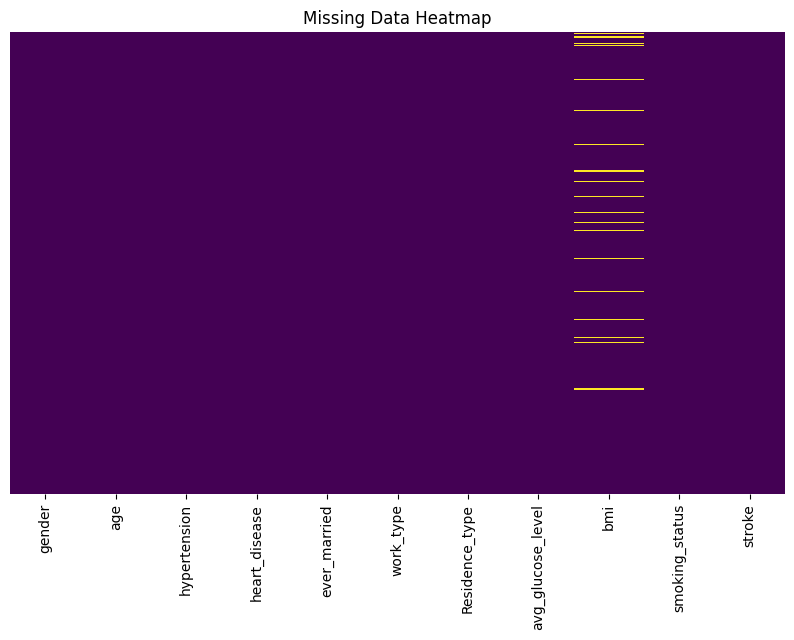

In [45]:
plot_missing_heatmap(df)

/usr/local/lib/python3.11/dist-packages/seaborn/categorical.py:645: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  g_vals = grouped_vals.get_group(g)


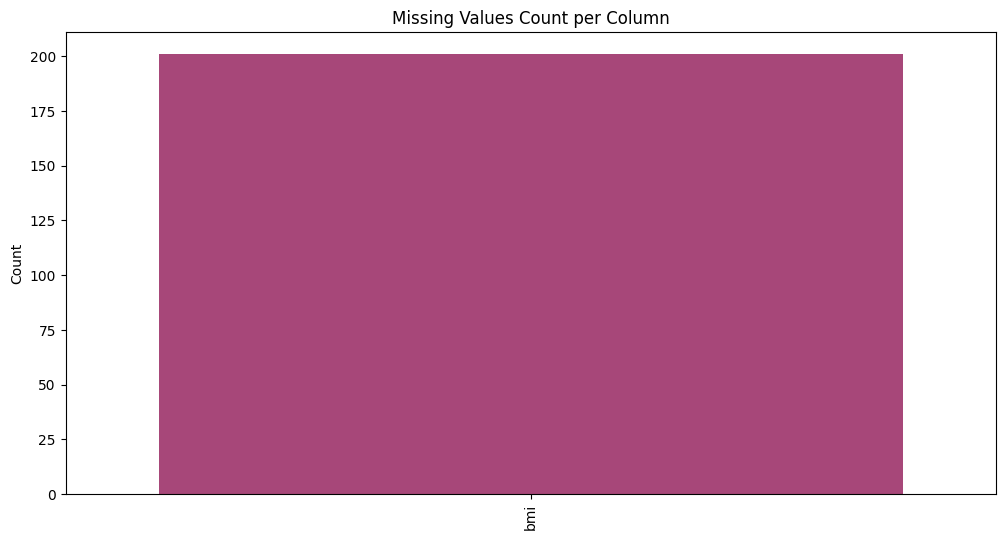

In [46]:
plot_missing_bar(df)

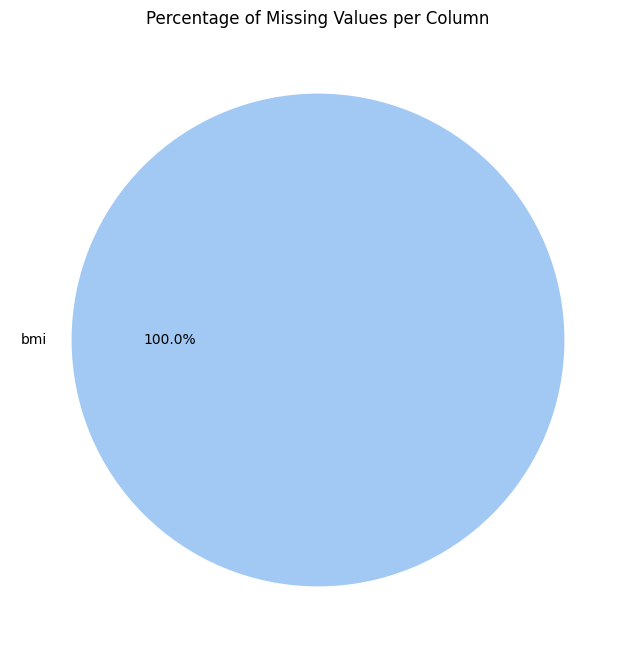

In [47]:
plot_missing_pie(df)

In [48]:
df.head(3)

/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: invalid value encountered in greater
  has_large_values = (abs_vals > 1e6).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in less
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in greater
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1


In [49]:
df.isnull().sum()

gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

# Dealing with all the numerical features(nulls/scailing)

In [50]:
numerical = df.select_dtypes(include=['int64','float64']).columns.tolist()
numerical

['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi', 'stroke']

/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


<Axes: xlabel='age', ylabel='Count'>

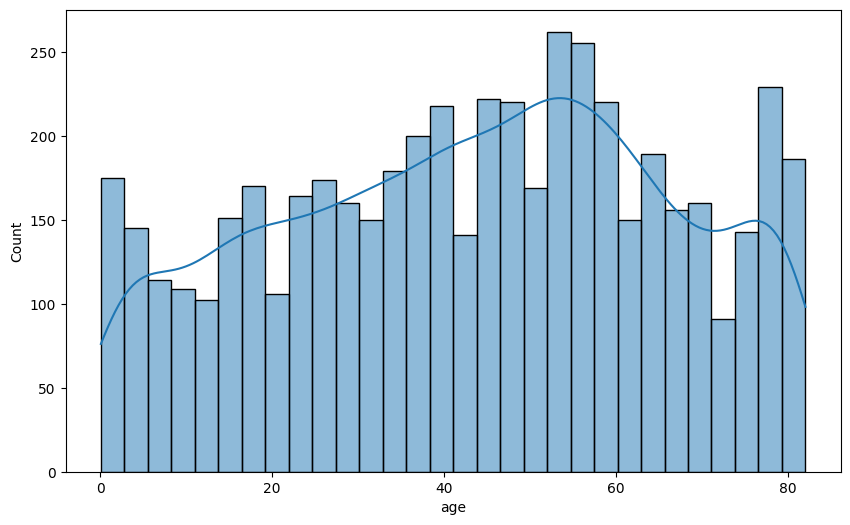

In [51]:
plt.figure(figsize=(10,6))
sns.histplot(df.age,kde=True,bins=30)

In [52]:
df.age[df.age < 1].value_counts()

age
0.88    5
0.32    5
0.24    5
0.72    5
0.56    5
0.64    4
0.80    4
0.48    3
0.16    3
0.40    2
0.08    2
Name: count, dtype: int64

# Is that a mistake let's check

In [53]:
df[df.age < 1]

/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: invalid value encountered in greater
  has_large_values = (abs_vals > 1e6).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in less
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in greater
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
363,Female,0.64,0,0,No,children,Urban,83.82,24.9,Unknown,0
376,Female,0.88,0,0,No,children,Rural,88.11,15.5,Unknown,0
564,Female,0.32,0,0,No,children,Rural,73.71,16.2,Unknown,0
982,Male,0.88,0,0,No,children,Rural,157.57,19.2,Unknown,0
996,Male,0.24,0,0,No,children,Rural,118.87,16.3,Unknown,0
1093,Female,0.32,0,0,No,children,Rural,55.86,16.0,Unknown,0
1206,Female,0.72,0,0,No,children,Urban,66.36,23.0,Unknown,0
1317,Male,0.80,0,0,No,children,Rural,98.67,17.5,Unknown,0
1600,Male,0.40,0,0,No,children,Urban,109.56,14.3,Unknown,0
1614,Female,0.08,0,0,No,children,Urban,139.67,14.1,Unknown,0


In [54]:
df.work_type[df.age < 1] == 'children'

363     True
376     True
564     True
982     True
996     True
1093    True
1206    True
1317    True
1600    True
1614    True
1808    True
1975    True
1999    True
2008    True
2012    True
2030    True
2358    True
2481    True
2490    True
2579    True
2630    True
2801    True
2875    True
2898    True
3251    True
3295    True
3392    True
3440    True
3618    True
3626    True
3859    True
3894    True
3968    True
4007    True
4021    True
4053    True
4293    True
4409    True
4581    True
4645    True
4910    True
4929    True
5089    True
Name: work_type, dtype: bool

It appears that it's not a mistake these are children(infants)

In [55]:
df.hypertension.value_counts()

hypertension
0    4612
1     498
Name: count, dtype: int64

([<matplotlib.patches.Wedge at 0x7e711c49f410>,
 [Text(-1.3348942113978373, 0.42196853481811436, 'No Hypertension'),
  Text(1.1441950298751005, -0.3616873423402018, 'Hypertension')],
 [Text(-0.8581462787557526, 0.2712654866687878, '90.3%'),
  Text(0.6674471007604752, -0.21098428303178438, '9.7%')])

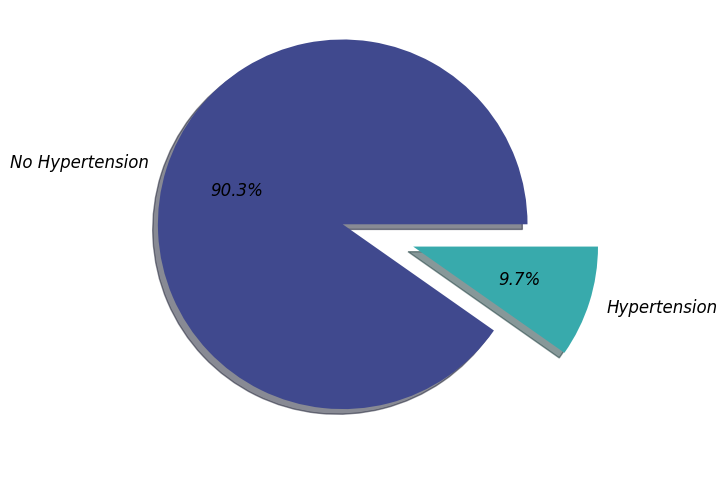

In [56]:
plt.figure(figsize=(10,6))
plt.pie(df.hypertension.value_counts(),labels=['No Hypertension','Hypertension'],autopct='%1.1f%%',
        colors=sns.color_palette('mako',2),explode=(0.3,0.1),shadow=True,textprops={'fontsize':12,'style':'italic'})

In [57]:
df.heart_disease.value_counts()

heart_disease
0    4834
1     276
Name: count, dtype: int64

([<matplotlib.patches.Wedge at 0x7e711c5837d0>,
 [Text(-1.3798936980729009, 0.23641781239723444, 'No Heart disease'),
  Text(1.182766015061574, -0.2026439084092213, 'Heart disease')],
 [Text(-0.8870745201897219, 0.1519828793982221, '94.6%'),
  Text(0.6899468421192514, -0.11820894657204575, '5.4%')])

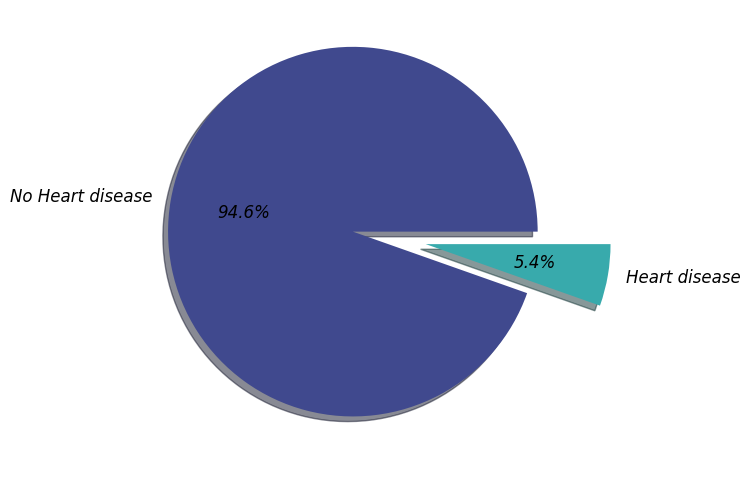

In [58]:
plt.figure(figsize=(10,6))
plt.pie(df.heart_disease.value_counts(),labels=['No Heart disease','Heart disease'],autopct='%1.1f%%',
        colors=sns.color_palette('mako',2),explode=(0.3,0.1),shadow=True,textprops={'fontsize':12,'style':'italic'})

/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


<Axes: xlabel='avg_glucose_level', ylabel='Count'>

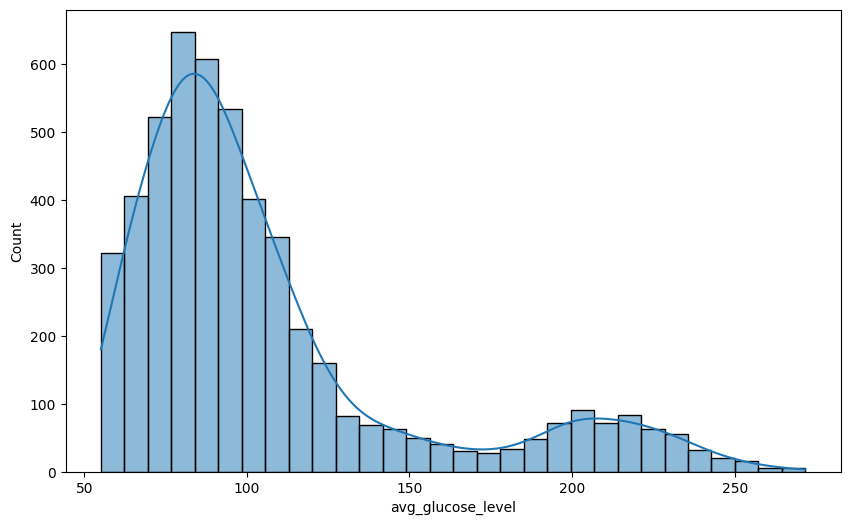

In [59]:
plt.figure(figsize=(10,6))
sns.histplot(df.avg_glucose_level,kde=True,bins=30)

In [60]:
df.avg_glucose_level.describe()

count    5110.000000
mean      106.147677
std        45.283560
min        55.120000
25%        77.245000
50%        91.885000
75%       114.090000
max       271.740000
Name: avg_glucose_level, dtype: float64

/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


<Axes: xlabel='bmi', ylabel='Count'>

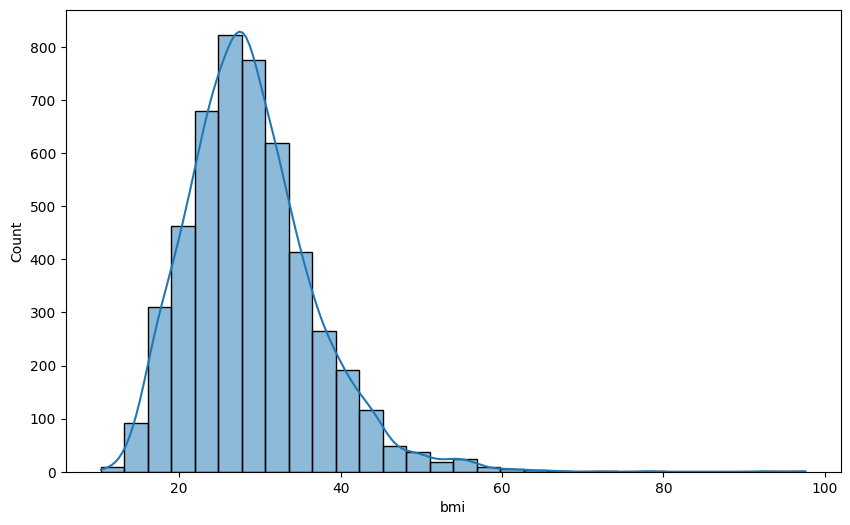

In [61]:
plt.figure(figsize=(10,6))
sns.histplot(df.bmi,kde=True,bins=30)

In [62]:
df.bmi.describe()

count    4909.000000
mean       28.893237
std         7.854067
min        10.300000
25%        23.500000
50%        28.100000
75%        33.100000
max        97.600000
Name: bmi, dtype: float64

***Dealing with the nulls***# 

In [64]:
df.bmi.fillna(df.bmi.mean(),inplace=True)

/tmp/ipykernel_36/799814321.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df.bmi.fillna(df.bmi.mean(),inplace=True)


In [65]:
df.isnull().sum()

gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64

# *Dealing with all the categorical features(nulls (if exists)/encoding)*

In [66]:
categories = df.select_dtypes(include=['object']).columns.tolist()
categories

['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']

In [67]:
df.gender.value_counts()

gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

***Dropping the Other as it should be female or male***

In [68]:
df.drop(df[df.gender == 'Other'].index,inplace=True)
df.reset_index(drop=True,inplace=True)

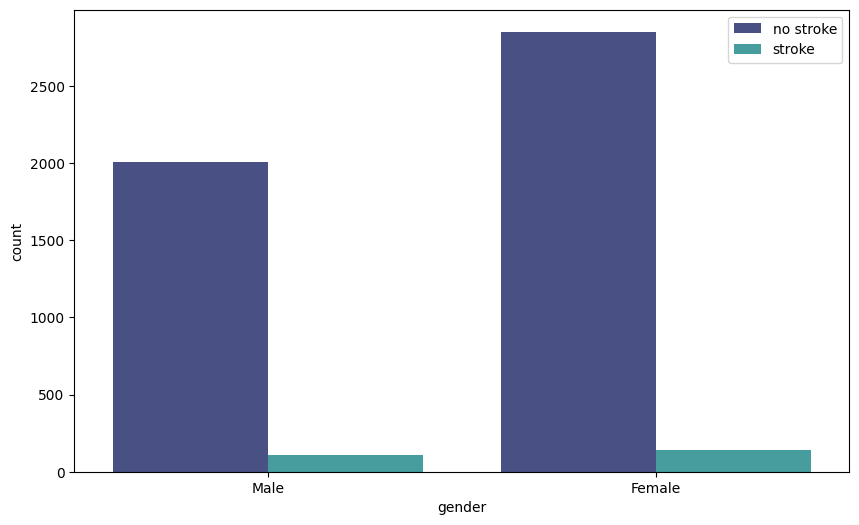

In [70]:
plt.figure(figsize=(10,6))
sns.countplot(x="gender", data=df, palette='mako',hue='stroke')
plt.legend(['no stroke','stroke'])


***Mapping the gender***

In [72]:
df.gender = df.gender.map({'Male':0,'Female':1})

In [73]:
df.ever_married.value_counts()

ever_married
Yes    3353
No     1756
Name: count, dtype: int64

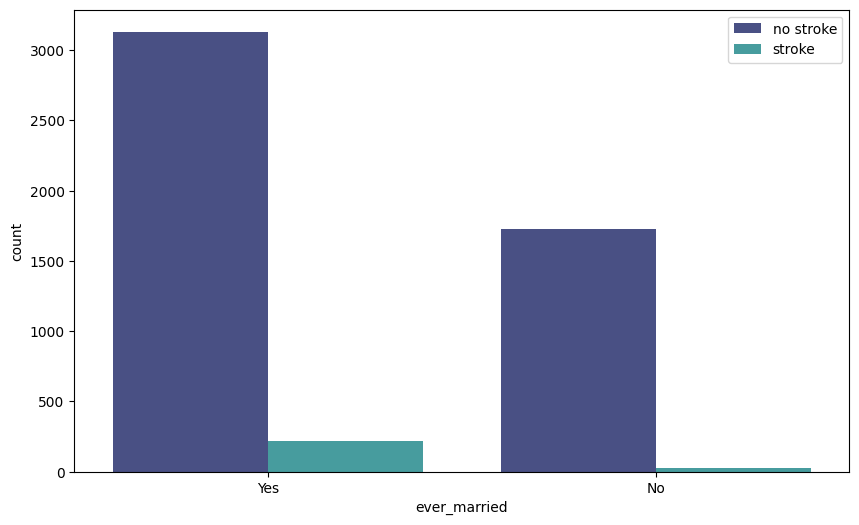

In [75]:
plt.figure(figsize=(10,6))
sns.countplot(x="ever_married", data=df, palette='mako',hue='stroke')
plt.legend(['no stroke','stroke'])

***Mapping the ever_married***

In [76]:
df.ever_married = df.ever_married.map({'No':0,'Yes':1})

In [77]:
df.work_type.value_counts()

work_type
Private          2924
Self-employed     819
children          687
Govt_job          657
Never_worked       22
Name: count, dtype: int64

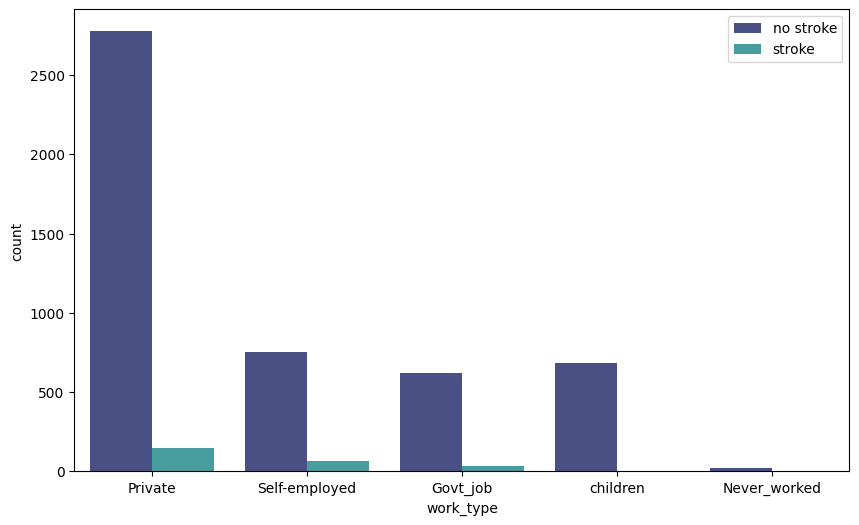

In [79]:
plt.figure(figsize=(10,6))
sns.countplot(x="work_type", data=df, palette='mako',hue='stroke')
plt.legend(['no stroke','stroke'])

***Mapping the work_type***

In [80]:
df.work_type = df.work_type.map({'Private':0,'Self-employed':1,'children':2,'Govt_job':3,'Never_worked':4})

In [81]:
df.Residence_type.value_counts()

Residence_type
Urban    2596
Rural    2513
Name: count, dtype: int64

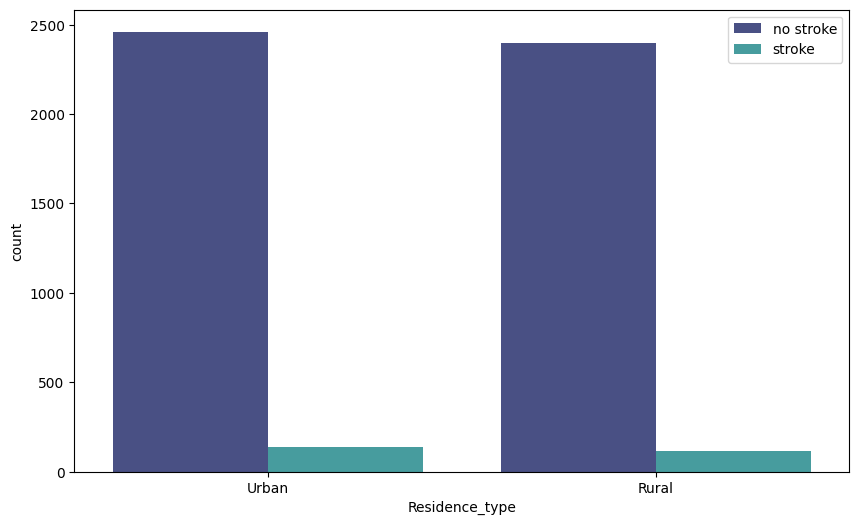

In [82]:
plt.figure(figsize=(10,6))
sns.countplot(x="Residence_type", data=df, palette='mako',hue='stroke')
plt.legend(['no stroke','stroke'])

***Mapping the Residence_type***

In [83]:
df.Residence_type = df.Residence_type.map({'Urban':0,'Rural':1})

In [84]:
df.smoking_status.value_counts()

smoking_status
never smoked       1892
Unknown            1544
formerly smoked     884
smokes              789
Name: count, dtype: int64

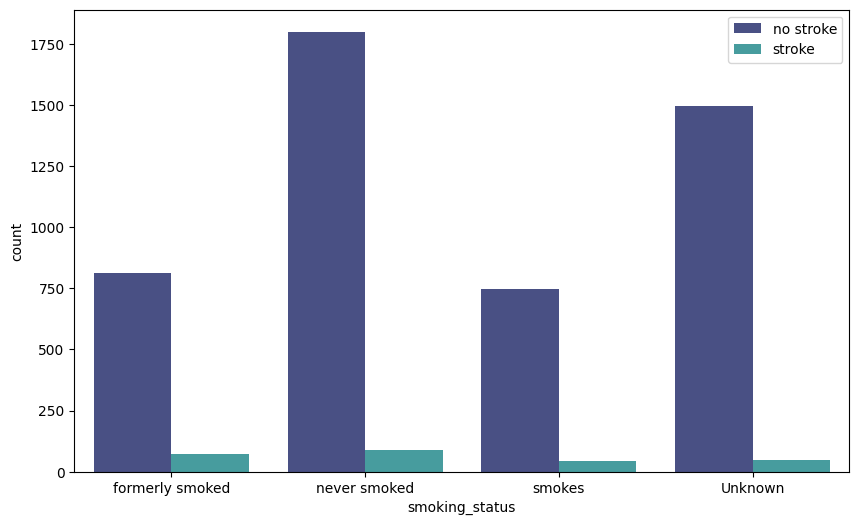

In [85]:
plt.figure(figsize=(10,6))
sns.countplot(x="smoking_status", data=df, palette='mako',hue='stroke')
plt.legend(['no stroke','stroke'])

***Mapping the smoking_status***

In [86]:
df.smoking_status = df.smoking_status.map({'never smoked':0,'formerly smoked':1,'smokes':2,'Unknown':3})

In [87]:
df.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,0,67.0,0,1,1,0,0,228.69,36.600000,1,1
1,1,61.0,0,0,1,1,1,202.21,28.893237,0,1
2,0,80.0,0,1,1,0,1,105.92,32.500000,0,1
3,1,49.0,0,0,1,0,0,171.23,34.400000,2,1
4,1,79.0,1,0,1,1,1,174.12,24.000000,0,1


In [88]:
df.isnull().sum()

gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64

In [89]:
def handle_binary_missing(df, binary_cols, imputation_method='mode'):
    """
    Handle missing values for binary columns using specified imputation method.
    """

    for col in binary_cols:
        if imputation_method == 'mode':
            mode_value = df[col].mode()[0]
            df[col] = df[col].fillna(mode_value)
            print(f"🔹 Imputed missing values in binary column '{col}' with mode: {mode_value}")
        elif imputation_method == 'mean': 
            mean_value = df[col].mean()
            df[col] = df[col].fillna(mean_value)
            print(f"🔹 Imputed missing values in binary column '{col}' with mean: {mean_value}")
            
    return df

In [90]:
def handle_categorical_missing(df, categorical_cols, imputation_method='mode'):
    """
    Handle missing values for categorical columns using specified imputation method.
    """

    for col in categorical_cols:
        if imputation_method == 'mode':
            mode_value = df[col].mode()[0]
            df[col] = df[col].fillna(mode_value)
            print(f"🔹 Imputed missing values in categorical column '{col}' with mode: {mode_value}")
        elif imputation_method == 'most_frequent':
            most_frequent_value = df[col].value_counts().idxmax()
            df[col] = df[col].fillna(most_frequent_value)  
            print(f"🔹 Imputed missing values in categorical column '{col}' with most frequent: {most_frequent_value}")
            
    return df

In [91]:
def handle_numerical_missing(df, numerical_cols, imputation_method='median'):
    """
    Handle missing values for numerical columns using specified imputation method.
    """

    for col in numerical_cols:
        if df[col].dtype in ['int64', 'float64']:
            if imputation_method == 'mean':
                mean_value = df[col].mean()
                df[col] = df[col].fillna(mean_value) 
                print(f"🔹 Imputed missing values in numerical column '{col}' with mean: {mean_value}")
            elif imputation_method == 'median':
                median_value = df[col].median()
                df[col] = df[col].fillna(median_value) 
                print(f"🔹 Imputed missing values in numerical column '{col}' with median: {median_value}")
            elif imputation_method == 'most_frequent':
                most_frequent_value = df[col].value_counts().idxmax()
                df[col] = df[col].fillna(most_frequent_value) 
                print(f"🔹 Imputed missing values in numerical column '{col}' with most frequent: {most_frequent_value}")
                
    return df

In [92]:
def handle_multivariate_imputation(df, imputation_method='knn'):
    """
    Handle multivariate imputation using KNN or Iterative Imputer.
    """
    
    if imputation_method == 'knn':
        print("🔹 Applying KNN Imputer...")
        knn_imputer = KNNImputer(n_neighbors=5)
        df_imputed = pd.DataFrame(knn_imputer.fit_transform(df), columns=df.columns)
        print("🔹 KNN Imputation applied.")
    else:
        print("❌ Invalid multivariate imputation method chosen.")
        return df
    
    return df_imputed

In [93]:
def handle_fill(df, fill_method='forward'):
    """
    Handle missing values using forward or backward fill.
    """

    if fill_method == 'forward':
        print("🔹 Applying forward fill...")
        df.fillna(method='ffill', inplace=True)
        print("🔹 Forward fill applied successfully.")
    elif fill_method == 'backward':
        print("🔹 Applying backward fill...")
        df.fillna(method='bfill', inplace=True)
        print("🔹 Backward fill applied successfully.")
    else:
        print("❌ Invalid fill method chosen.")

    return df

In [94]:
def classify_columns(df):
    """
    Classify columns into binary, numerical, and categorical types.
    """
    binary_cols = []
    numerical_cols = []
    categorical_cols = []
    
    for col in df.columns:
        if df[col].dtype in ['int64', 'float64']: 
            if df[col].nunique() == 2:  
                binary_cols.append(col)
            else:
                numerical_cols.append(col)
        elif df[col].dtype == 'object' or df[col].dtype.name == 'category':  
            if df[col].nunique() == 2:
                binary_cols.append(col)
            else:
                categorical_cols.append(col)

    return {
        'binary': binary_cols,
        'numerical': numerical_cols,
        'categorical': categorical_cols
    }

In [98]:
df.head(10)

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,0,67.0,0,1,1,0,0,228.69,36.600000,1,1
1,1,61.0,0,0,1,1,1,202.21,28.893237,0,1
2,0,80.0,0,1,1,0,1,105.92,32.500000,0,1
3,1,49.0,0,0,1,0,0,171.23,34.400000,2,1
4,1,79.0,1,0,1,1,1,174.12,24.000000,0,1
5,0,81.0,0,0,1,0,0,186.21,29.000000,1,1
6,0,74.0,1,1,1,0,1,70.09,27.400000,0,1
7,1,69.0,0,0,0,0,0,94.39,22.800000,0,1
8,1,59.0,0,0,1,0,1,76.15,28.893237,3,1
9,1,78.0,0,0,1,0,0,58.57,24.200000,3,1


In [95]:
classify_columns(df)

{'binary': ['gender',
  'hypertension',
  'heart_disease',
  'ever_married',
  'Residence_type',
  'stroke'],
 'numerical': ['age',
  'work_type',
  'avg_glucose_level',
  'bmi',
  'smoking_status'],
 'categorical': []}

In [96]:
def filter_columns_by_null_percentage(df, column_classification, threshold=0.1):
    """
    Filters out columns from the classification lists that have more than the specified threshold of missing values.
    """
    filtered_classification = {'binary': [], 'numerical': [], 'categorical': []}
    missing_percentage = df.isnull().mean()
    
    for col_type in column_classification:
        for col in column_classification[col_type]:
            if missing_percentage[col] <= threshold: 
                filtered_classification[col_type].append(col)
            else:
                print(f"🔹 Column '{col}' has more than {threshold*100}% missing values and is removed.")
    
    return filtered_classification

In [99]:
column_classification = {
    'binary': ['gender',
  'hypertension',
  'heart_disease',
  'ever_married',
  'Residence_type',
  'stroke'],
 'numerical': ['age',
  'work_type',
  'avg_glucose_level',
  'bmi',
  'smoking_status'],
 'categorical': []
}

filtered_classification = filter_columns_by_null_percentage(df, column_classification, threshold=0.1)
print(filtered_classification)

{'binary': ['gender', 'hypertension', 'heart_disease', 'ever_married', 'Residence_type', 'stroke'], 'numerical': ['age', 'work_type', 'avg_glucose_level', 'bmi', 'smoking_status'], 'categorical': []}


In [102]:
# df.head()
# df.isnull().sum()


In [103]:
handle_binary_missing(df, filtered_classification["binary"], imputation_method='mode')

🔹 Imputed missing values in binary column 'gender' with mode: 1
🔹 Imputed missing values in binary column 'hypertension' with mode: 0
🔹 Imputed missing values in binary column 'heart_disease' with mode: 0
🔹 Imputed missing values in binary column 'ever_married' with mode: 1
🔹 Imputed missing values in binary column 'Residence_type' with mode: 0
🔹 Imputed missing values in binary column 'stroke' with mode: 0


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,0,67.0,0,1,1,0,0,228.69,36.600000,1,1
1,1,61.0,0,0,1,1,1,202.21,28.893237,0,1
2,0,80.0,0,1,1,0,1,105.92,32.500000,0,1
3,1,49.0,0,0,1,0,0,171.23,34.400000,2,1
4,1,79.0,1,0,1,1,1,174.12,24.000000,0,1
...,...,...,...,...,...,...,...,...,...,...,...
5104,1,80.0,1,0,1,0,0,83.75,28.893237,0,0
5105,1,81.0,0,0,1,1,0,125.20,40.000000,0,0
5106,1,35.0,0,0,1,1,1,82.99,30.600000,0,0
5107,0,51.0,0,0,1,0,1,166.29,25.600000,1,0


In [104]:
handle_numerical_missing(df, filtered_classification["numerical"], imputation_method='most_frequent')

🔹 Imputed missing values in numerical column 'age' with most frequent: 78.0
🔹 Imputed missing values in numerical column 'work_type' with most frequent: 0
🔹 Imputed missing values in numerical column 'avg_glucose_level' with most frequent: 93.88
🔹 Imputed missing values in numerical column 'bmi' with most frequent: 28.893236911794666
🔹 Imputed missing values in numerical column 'smoking_status' with most frequent: 0


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,0,67.0,0,1,1,0,0,228.69,36.600000,1,1
1,1,61.0,0,0,1,1,1,202.21,28.893237,0,1
2,0,80.0,0,1,1,0,1,105.92,32.500000,0,1
3,1,49.0,0,0,1,0,0,171.23,34.400000,2,1
4,1,79.0,1,0,1,1,1,174.12,24.000000,0,1
...,...,...,...,...,...,...,...,...,...,...,...
5104,1,80.0,1,0,1,0,0,83.75,28.893237,0,0
5105,1,81.0,0,0,1,1,0,125.20,40.000000,0,0
5106,1,35.0,0,0,1,1,1,82.99,30.600000,0,0
5107,0,51.0,0,0,1,0,1,166.29,25.600000,1,0


/tmp/ipykernel_36/1501797490.py:5: UserWarning: To output multiple subplots, the figure containing the passed axes is being cleared.
  df.hist(ax = ax)


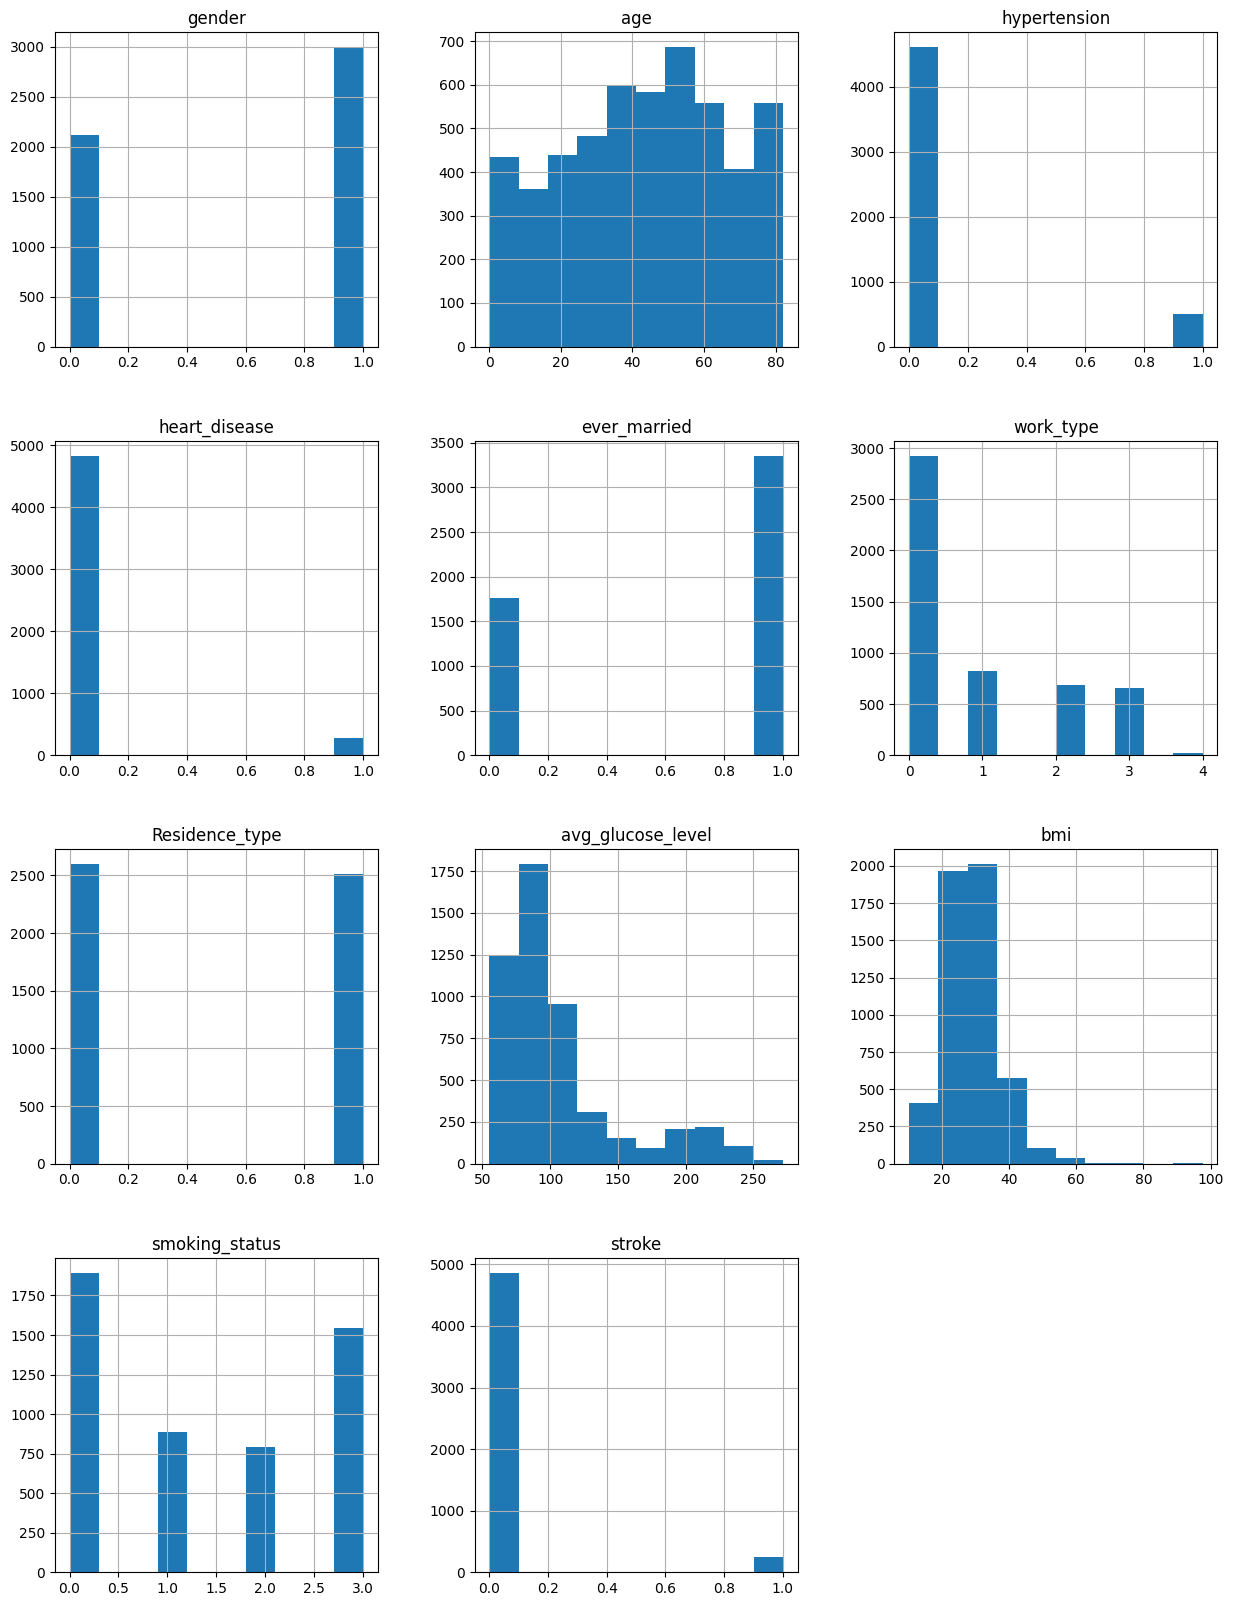

In [105]:
# Plot Histogram to See the Distribution of the Data

fig = plt.figure(figsize = (15,20))
ax = fig.gca()
df.hist(ax = ax)
plt.show()

Only stroke Partipants¶

/tmp/ipykernel_36/3082000209.py:6: UserWarning: To output multiple subplots, the figure containing the passed axes is being cleared.
  dataset_copy.hist(ax = ax)


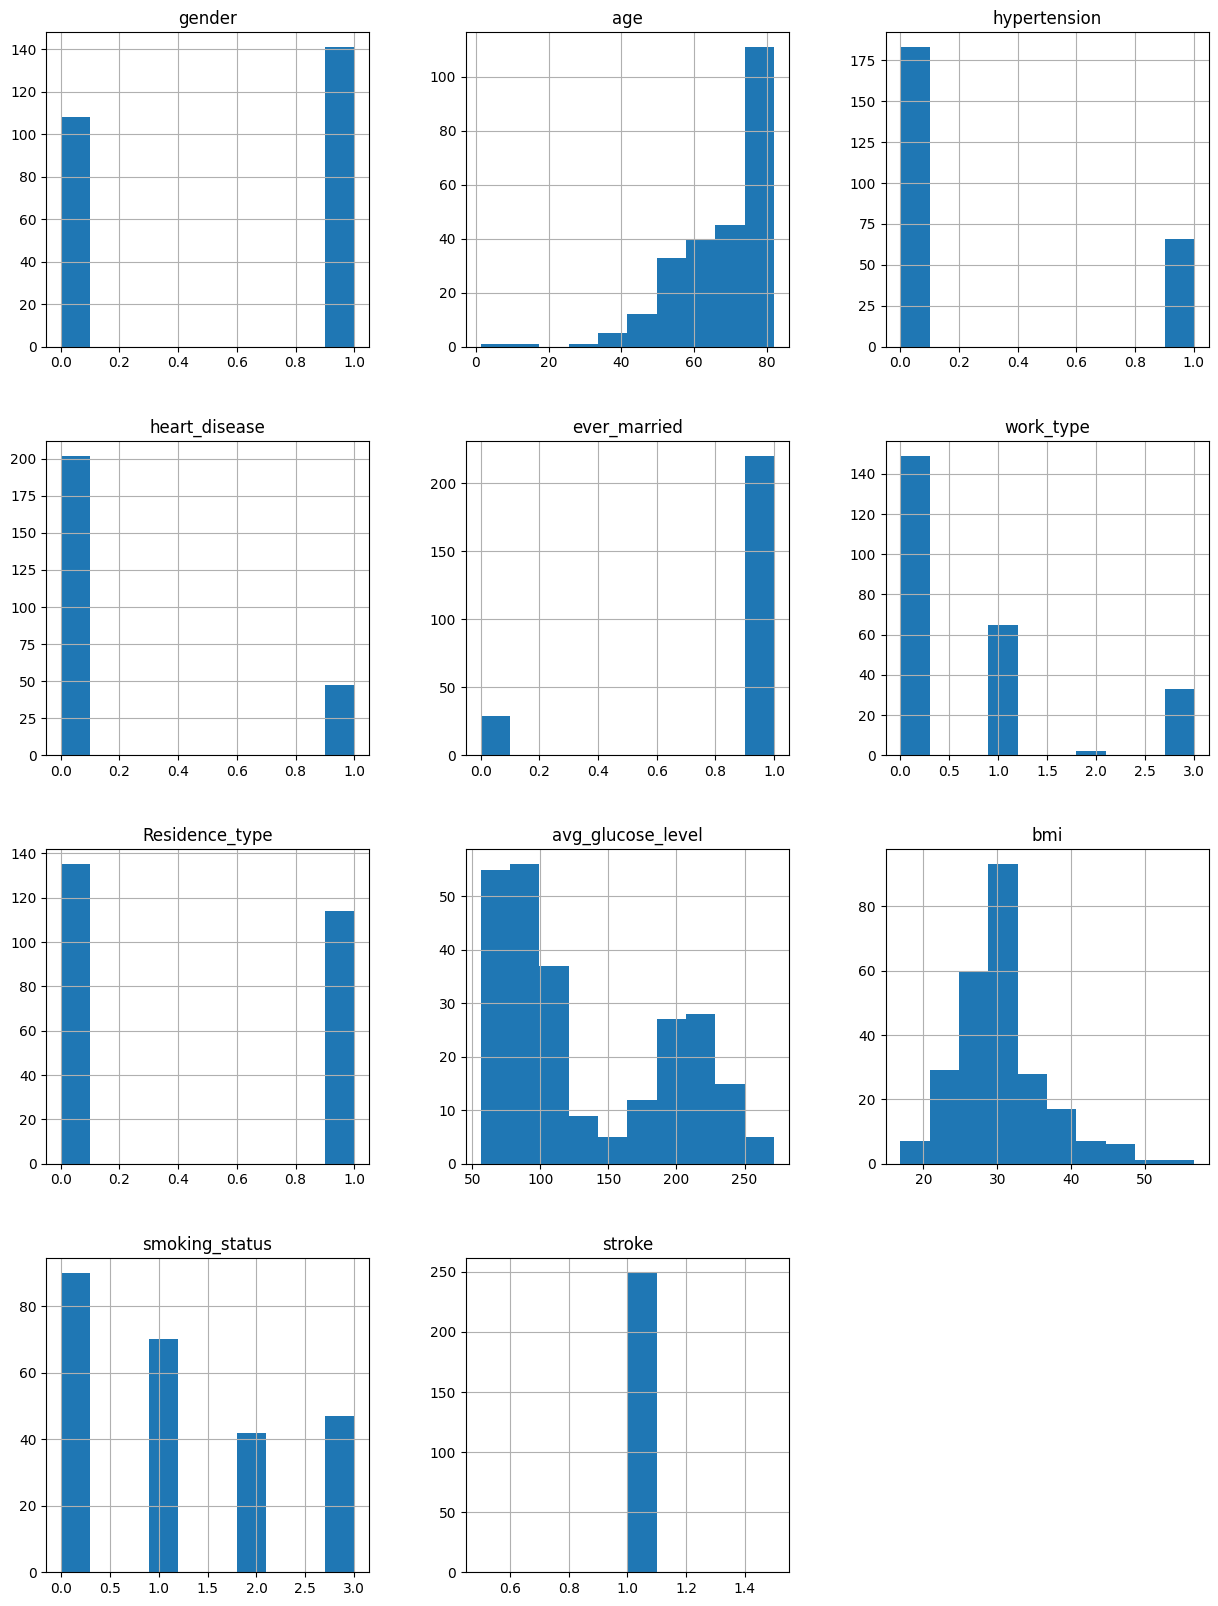

In [110]:
# Plot Histogram to See the Distribution of the Data for Heart Disease Cases
dataset_copy=df[df['stroke']==1]
columns=df.columns[:21]
fig = plt.figure(figsize = (15,20))
ax = fig.gca()
dataset_copy.hist(ax = ax)
plt.show()

histogram

In [121]:
def plot_binary_distribution(df, binary_cols):
    """Plot count plots for binary features to visualize the distribution of 0s and 1s."""
    num_plots = len(binary_cols)
    num_rows = (num_plots // 3) + (1 if num_plots % 3 != 0 else 0)

    fig, axes = plt.subplots(num_rows, 3, figsize=(15, num_rows * 5))
    axes = axes.flatten()

    for i, col in enumerate(binary_cols):
        sns.countplot(x=col, data=df, palette='Set2', ax=axes[i])
        axes[i].set_title(f"Count Plot of {col}")
        axes[i].set_xlabel(col)
        axes[i].set_ylabel("Count")

    # Hide any extra subplots
    for i in range(num_plots, len(axes)):
        axes[i].axis('off')

    plt.tight_layout()
    plt.show()


boxplot

In [112]:
def plot_binary_countplots(df, binary_cols):
    """Plot count plots for binary features to visualize 0/1 distribution."""
    num_plots = len(binary_cols)
    num_rows = (num_plots // 3) + (1 if num_plots % 3 != 0 else 0)

    fig, axes = plt.subplots(num_rows, 3, figsize=(15, num_rows * 5))
    axes = axes.flatten()

    for i, col in enumerate(binary_cols):
        sns.countplot(x=col, data=df, palette='pastel', ax=axes[i])
        axes[i].set_title(f"Count Plot of {col}")
        axes[i].set_xlabel(col)
        axes[i].set_ylabel("Count")

    for i in range(num_plots, len(axes)):
        axes[i].axis('off')

    plt.tight_layout()
    plt.show()


plot_kde

In [113]:
def plot_kde(df, numerical_cols):
    """Plot KDE (Kernel Density Estimate) for numerical features to visualize smooth distributions."""
    num_plots = len(numerical_cols)
    num_rows = (num_plots // 3) + (1 if num_plots % 3 != 0 else 0)
    
    fig, axes = plt.subplots(num_rows, 3, figsize=(15, num_rows * 5))
    axes = axes.flatten()
    
    for i, col in enumerate(numerical_cols):
        sns.kdeplot(df[col], shade=True, color='blue', alpha=0.5, ax=axes[i])
        axes[i].set_title(f"KDE of {col}")
        axes[i].set_xlabel(col)
        axes[i].set_ylabel("Density")
    
    for i in range(num_plots, len(axes)):
        axes[i].axis('off') 
    
    plt.tight_layout()
    plt.show()

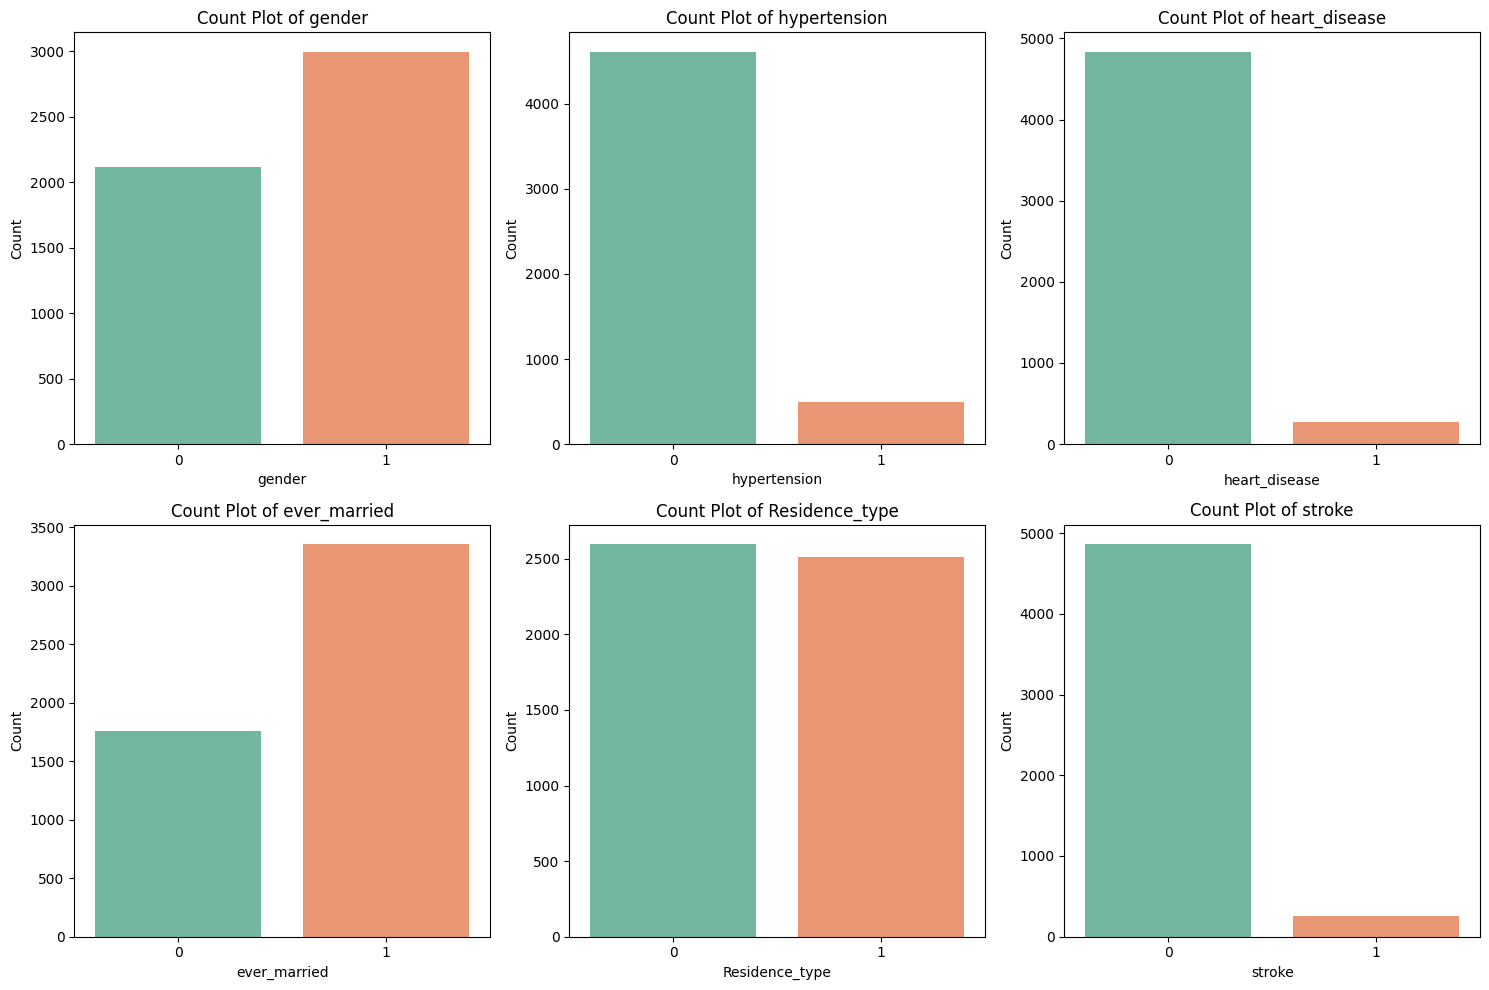

In [122]:
plot_binary_distribution(df, filtered_classification["binary"])


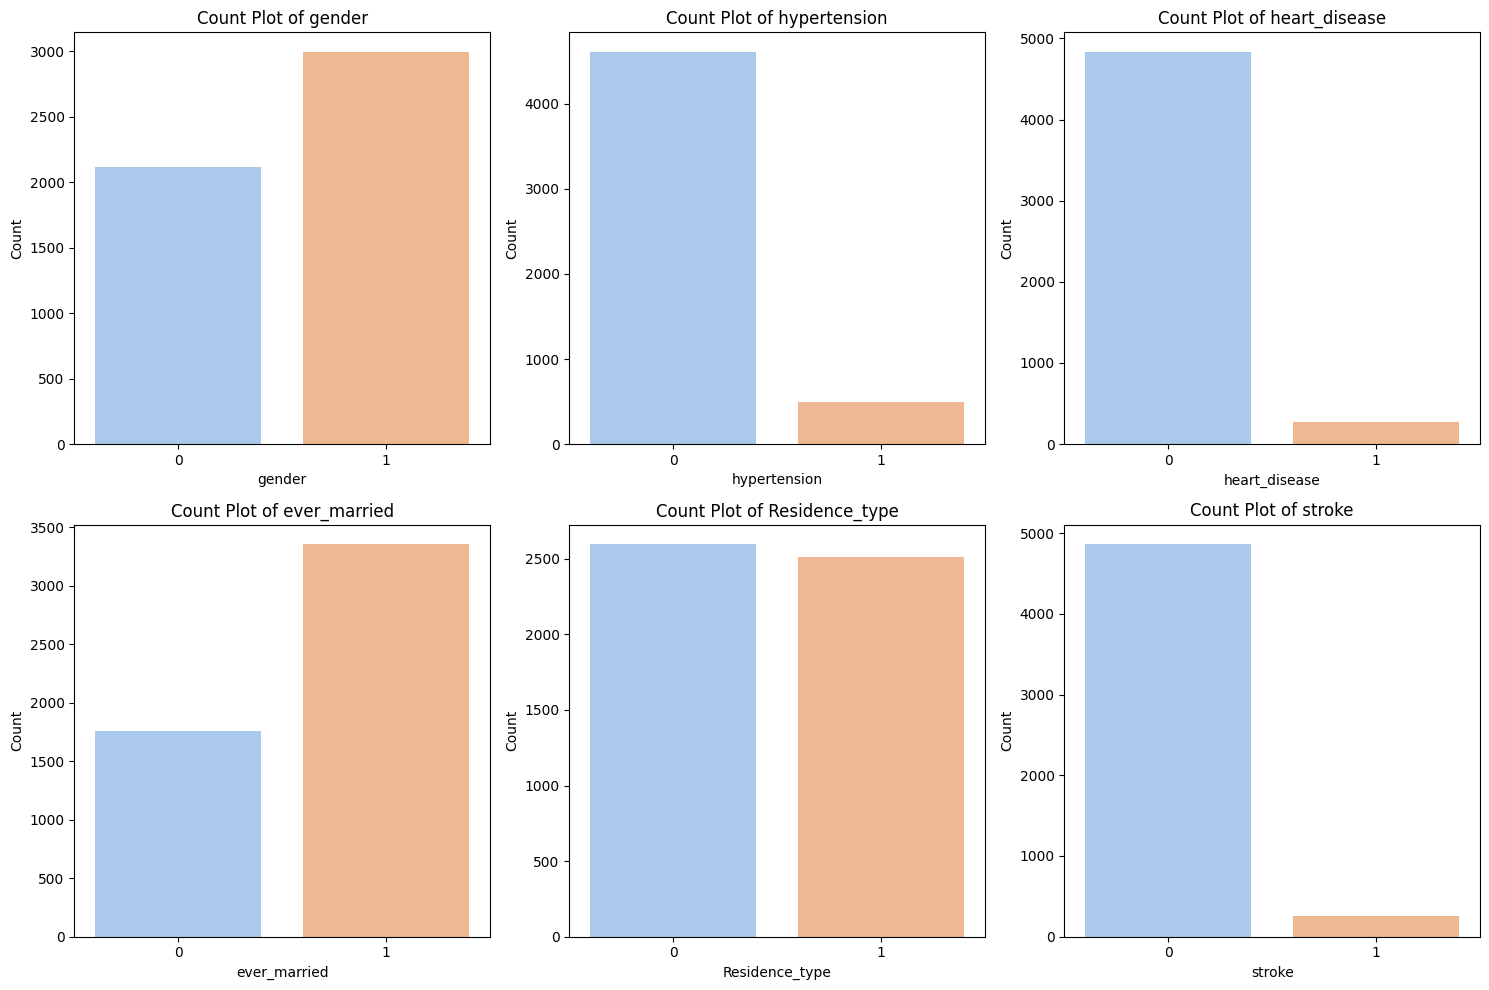

In [119]:
plot_binary_countplots(df, filtered_classification["binary"])


/tmp/ipykernel_36/4139792666.py:10: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(df[col], shade=True, color='blue', alpha=0.5, ax=axes[i])
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/tmp/ipykernel_36/4139792666.py:10: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(df[col], shade=True, color='blue', alpha=0.5, ax=axes[i])
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.


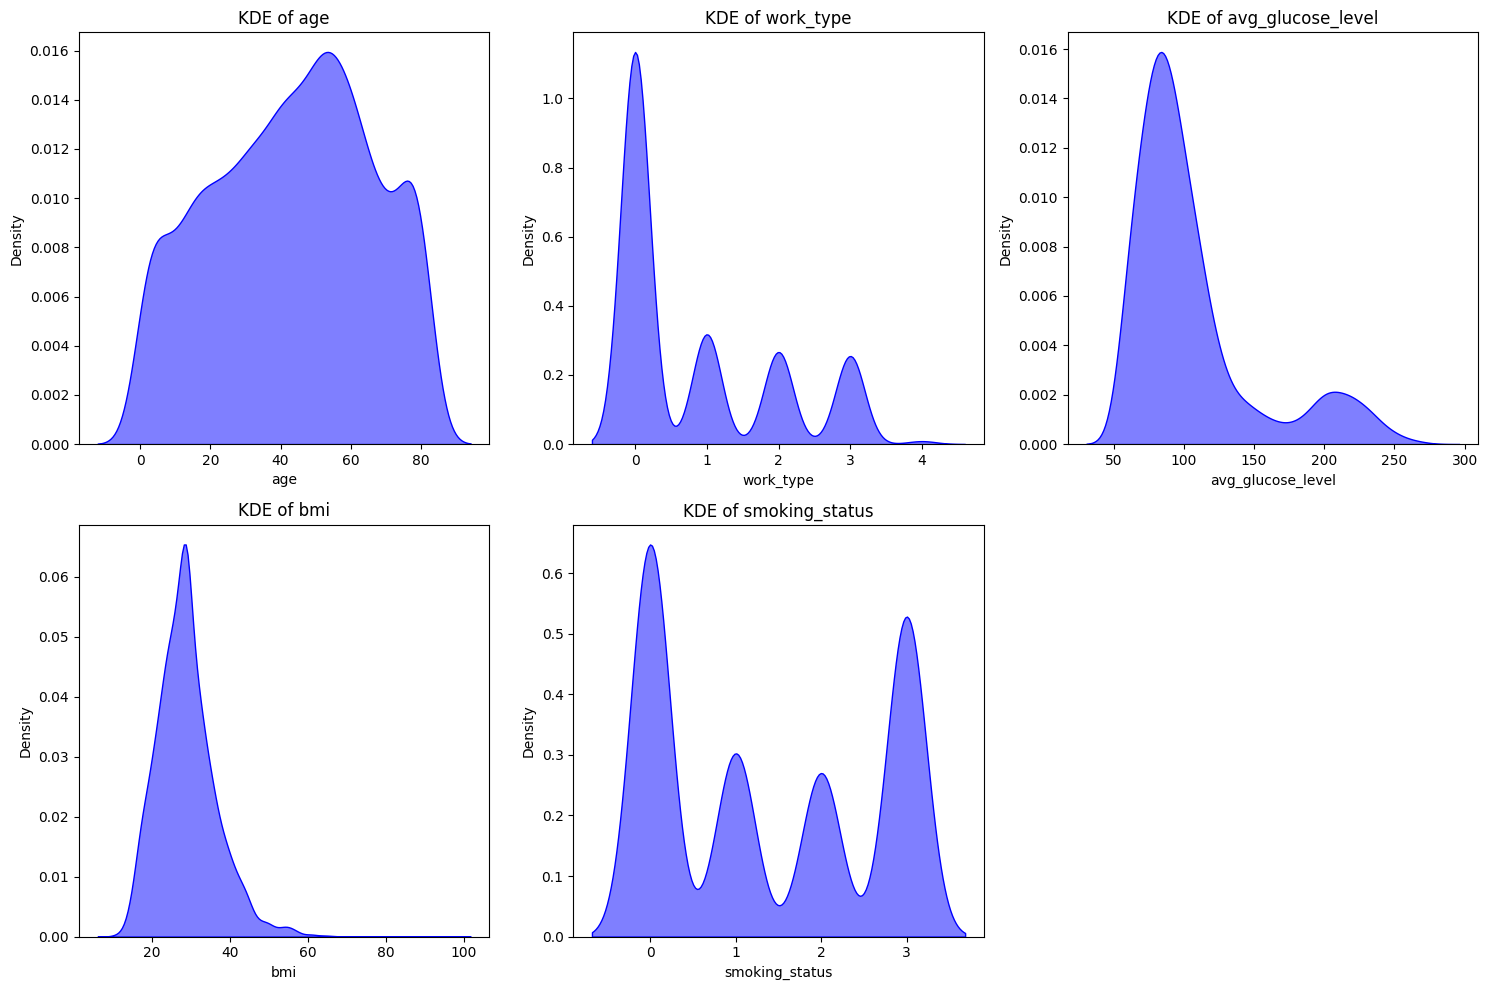

In [123]:
plot_kde(df, filtered_classification["numerical"])

In [115]:
def plot_barplot(df, categorical_cols):
    """Plot bar plots for categorical features to visualize the distribution of different categories."""
    num_plots = len(categorical_cols)
    num_rows = (num_plots // 3) + (1 if num_plots % 3 != 0 else 0) 
    
    fig, axes = plt.subplots(num_rows, 3, figsize=(15, num_rows * 5))
    axes = axes.flatten() 
    
    for i, col in enumerate(categorical_cols):
        sns.countplot(x=df[col], palette="Set2", ax=axes[i])
        axes[i].set_title(f"Bar Plot of {col}")
        axes[i].set_xlabel(col)
        axes[i].set_ylabel("Count")
    
    for i in range(num_plots, len(axes)):
        axes[i].axis('off') 
    
    plt.tight_layout()
    plt.show()

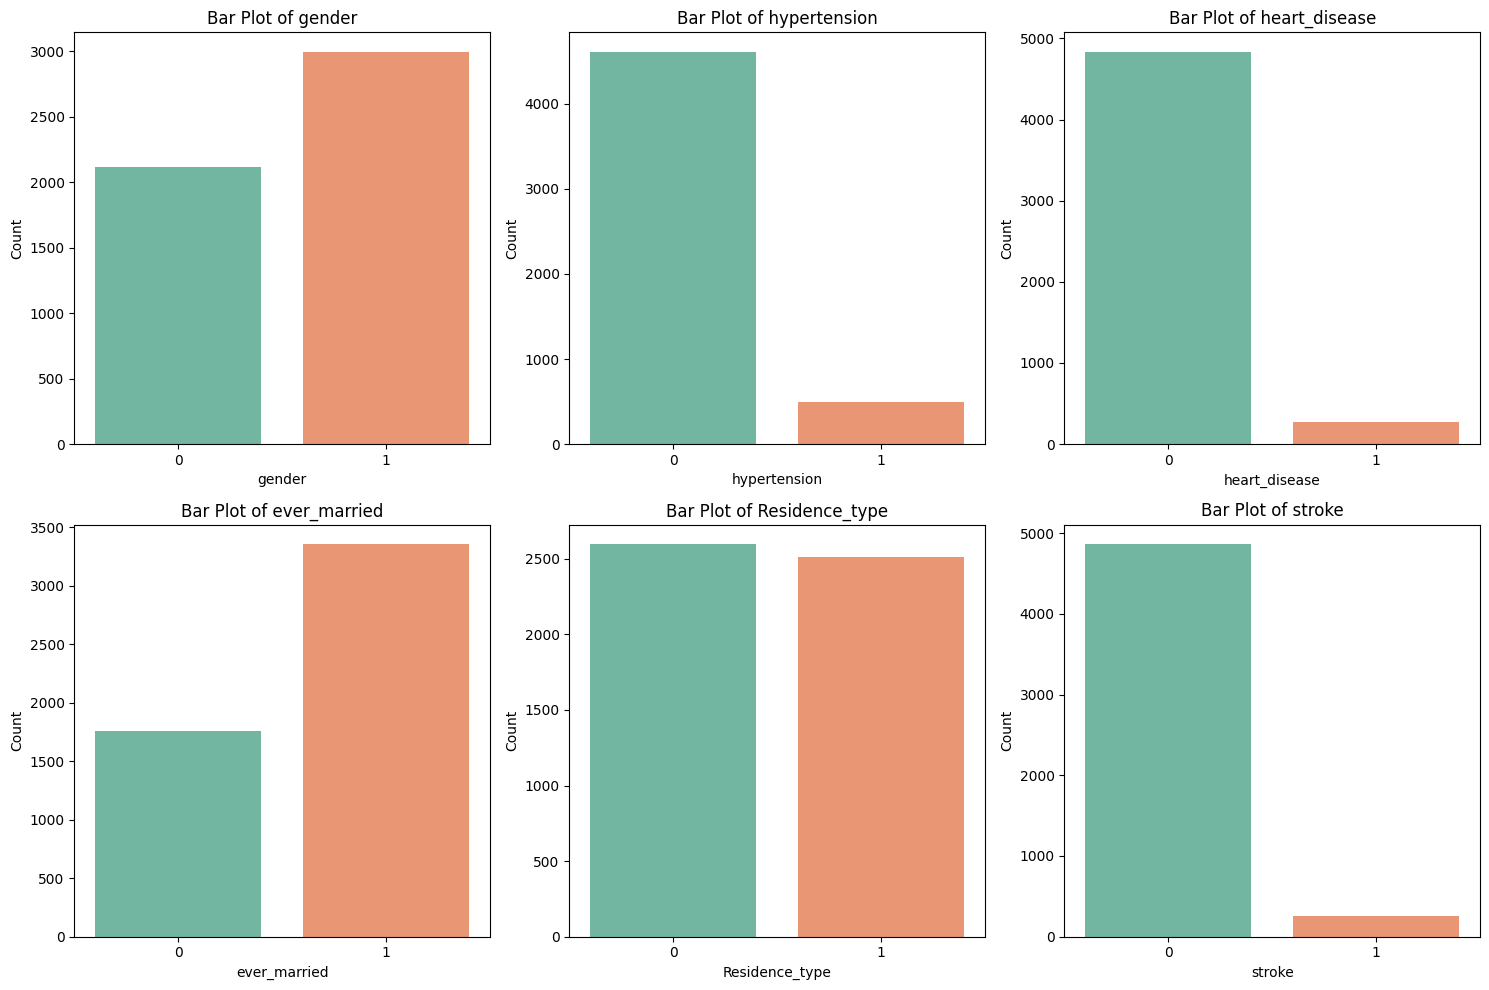

In [116]:
plot_barplot(df, filtered_classification["binary"])

In [117]:
# At Risk (Binary)
# Check for class imbalance
df['stroke'].value_counts()/len(df)

stroke
0    0.951262
1    0.048738
Name: count, dtype: float64

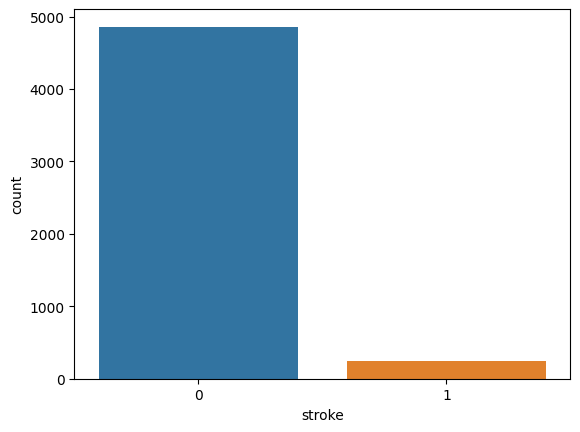

In [118]:
sns.countplot(x='stroke',data=df)
plt.show()

# 5. Outlier Detection

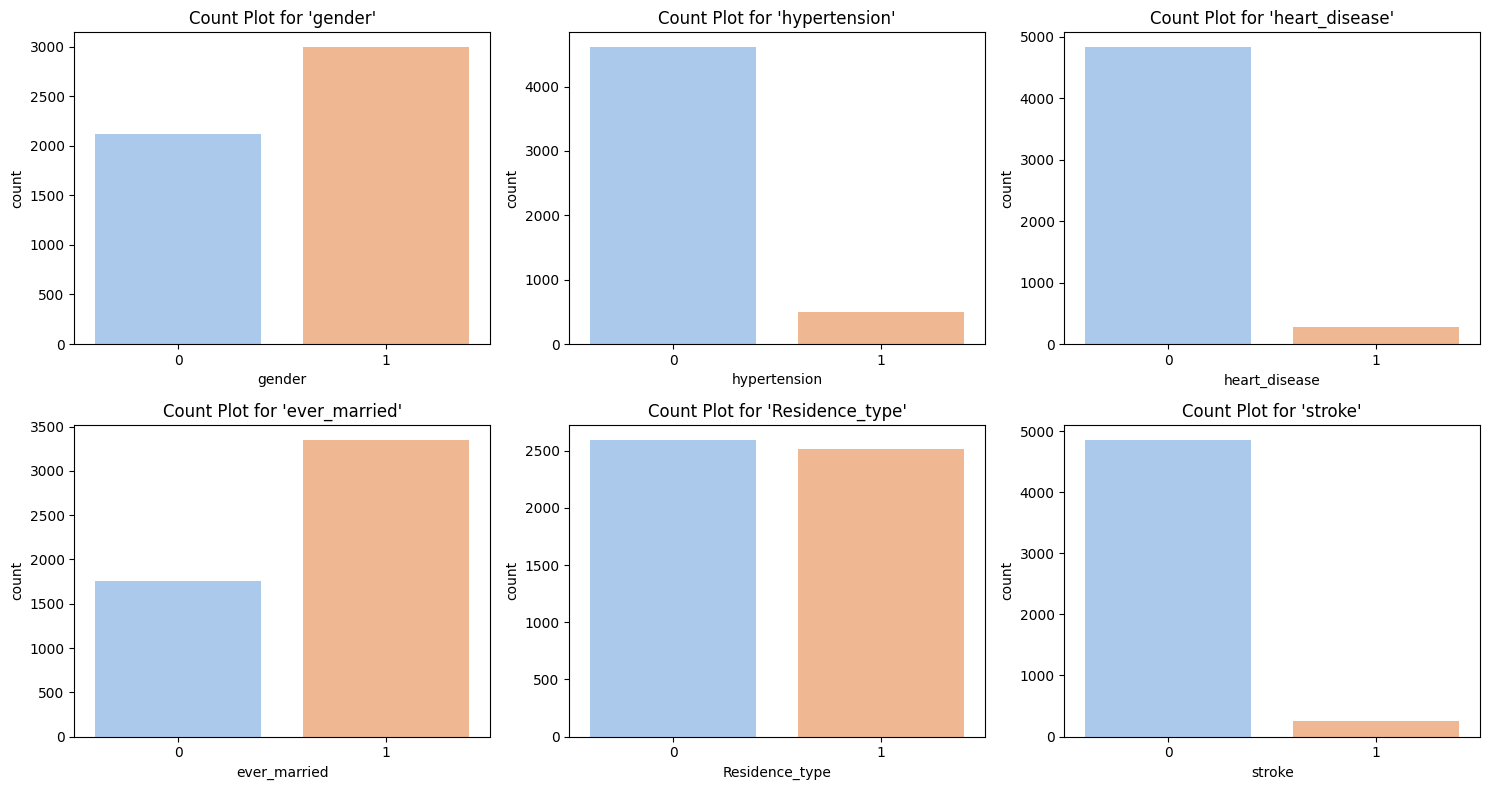

In [127]:


# Select binary columns (only those with 2 unique values: 0 and 1)
binary_cols = [col for col in df.columns if df[col].nunique() == 2 and df[col].dtype in ['int64', 'float64']]

# Plot count plots for each binary feature
num_plots = len(binary_cols)
num_rows = (num_plots // 3) + (1 if num_plots % 3 != 0 else 0)

fig, axes = plt.subplots(num_rows, 3, figsize=(15, num_rows * 4))
axes = axes.flatten()

for i, col in enumerate(binary_cols):
    sns.countplot(x=col, data=df, ax=axes[i], palette='pastel')
    axes[i].set_title(f"Count Plot for '{col}'")
    axes[i].set_xticks([0, 1])
    
# Hide unused subplots if any
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


In [125]:
def plot_binary_countplots(df, binary_cols):
    """Plot count plots for binary features to visualize 0/1 distributions."""
    num_plots = len(binary_cols)
    num_rows = (num_plots // 3) + (1 if num_plots % 3 != 0 else 0)

    fig, axes = plt.subplots(num_rows, 3, figsize=(15, num_rows * 5))
    axes = axes.flatten()

    for i, col in enumerate(binary_cols):
        sns.countplot(x=col, data=df, palette='pastel', ax=axes[i])
        axes[i].set_title(f"Count Plot of {col}")
        axes[i].set_xlabel(col)
        axes[i].set_ylabel("Count")

    for j in range(num_plots, len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.show()


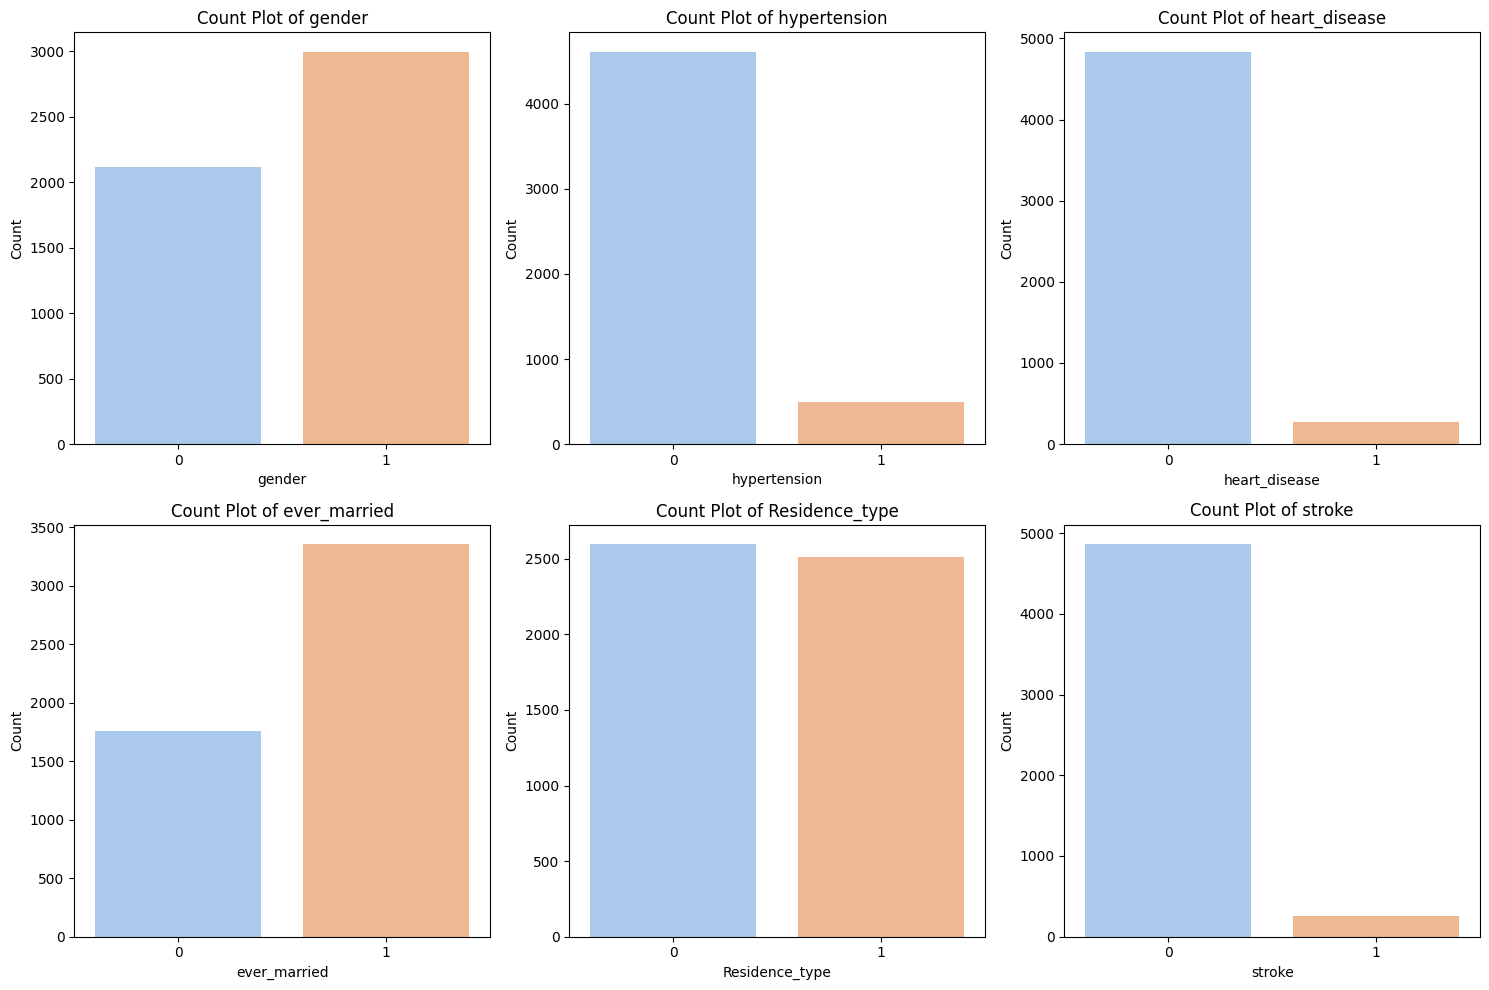

In [126]:
plot_binary_countplots(df, filtered_classification["binary"])


In [128]:
def plot_boxplots(df, numerical_cols):
    """Plot box plots for numerical features to visualize outliers."""
    num_plots = len(numerical_cols)
    num_rows = (num_plots // 3) + (1 if num_plots % 3 != 0 else 0)
    
    fig, axes = plt.subplots(num_rows, 3, figsize=(15, num_rows * 5))
    axes = axes.flatten()
    
    for i, col in enumerate(numerical_cols):
        sns.boxplot(x=df[col], ax=axes[i], color='lightcoral')
        axes[i].set_title(f"Boxplot of {col}")

    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

In [129]:
def plot_violinplots(df, numerical_cols):
    """Plot violin plots for numerical features to visualize distribution and outliers."""
    num_plots = len(numerical_cols)
    cols_per_row = 3 
    rows = (num_plots // cols_per_row) + (num_plots % cols_per_row > 0)  

    fig, axes = plt.subplots(rows, cols_per_row, figsize=(15, 5 * rows))
    axes = axes.flatten() 

    for i, col in enumerate(numerical_cols):
        sns.violinplot(x=df[col], ax=axes[i], color='teal')
        axes[i].set_title(f"Violin Plot of {col}")

    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

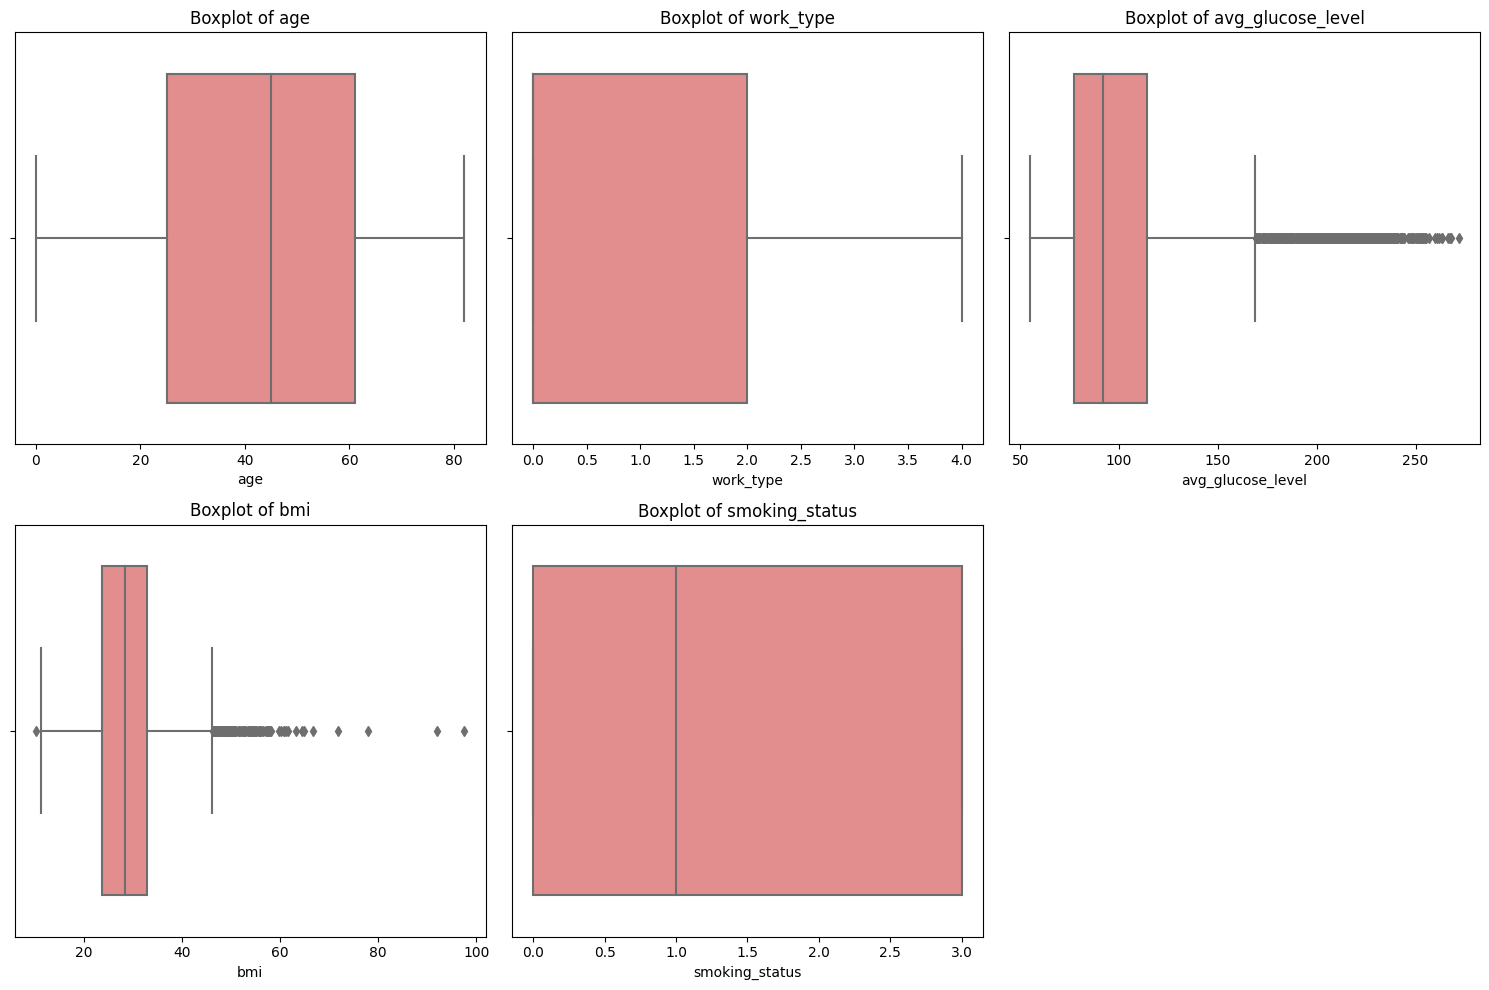

In [130]:
plot_boxplots(df, filtered_classification["numerical"])

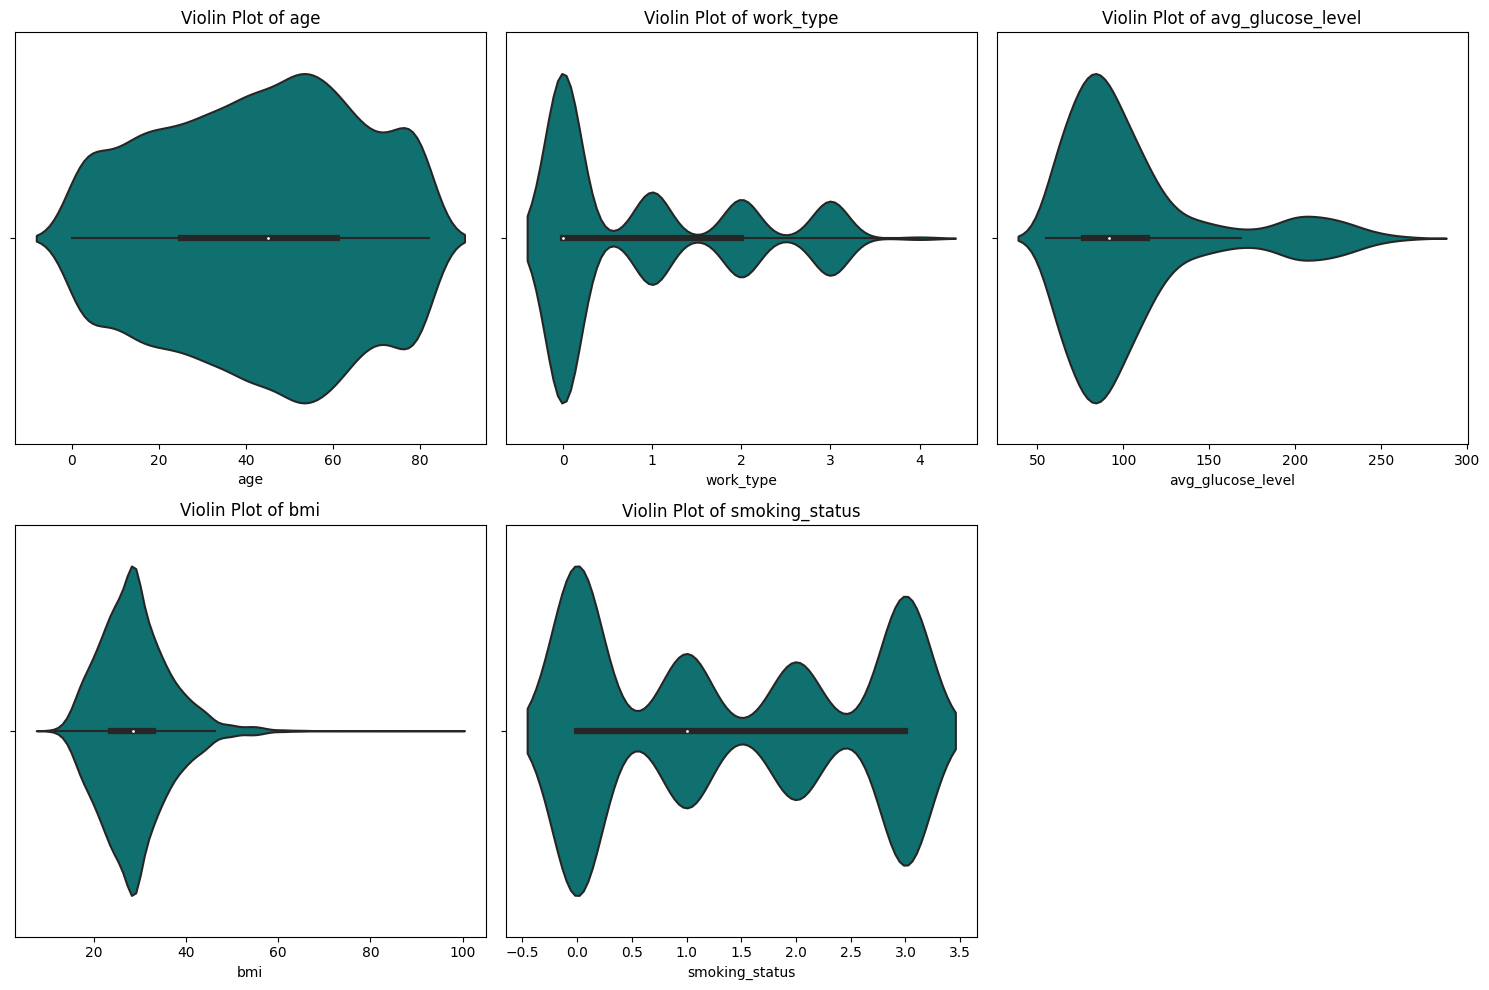

In [131]:
plot_violinplots(df, filtered_classification["numerical"])

In [132]:
def remove_outliers(df, numerical_cols, method="IQR"):
    """Remove rows containing outliers from numerical columns using IQR or Z-score."""
    df_clean = df.copy()
    
    for col in numerical_cols:
        if method == "IQR":
            Q1 = df[col].quantile(0.25)
            Q3 = df[col].quantile(0.75)
            IQR = Q3 - Q1
            lower_bound = Q1 - 1.5 * IQR
            upper_bound = Q3 + 1.5 * IQR
            df_clean = df_clean[(df_clean[col] >= lower_bound) & (df_clean[col] <= upper_bound)]
        elif method == "Z-score":
            mean = df[col].mean()
            std_dev = df[col].std()
            df_clean = df_clean[(np.abs((df[col] - mean) / std_dev) < 3)]
    
        print(f"🔹 Outliers removed in column '{col}' using {method} method.")
    
    return df_clean

In [134]:
def remove_outliers(df, numerical_cols, method="IQR"):
    """Remove rows containing outliers from non-binary numerical columns using IQR or Z-score."""
    df_clean = df.copy()
    
    for col in numerical_cols:
        unique_vals = df[col].dropna().unique()
        if len(unique_vals) <= 2 and set(unique_vals).issubset({0, 1}):
            print(f"⏭️ Skipping binary column '{col}' (only 0 and 1).")
            continue
        
        if method == "IQR":
            Q1 = df[col].quantile(0.25)
            Q3 = df[col].quantile(0.75)
            IQR = Q3 - Q1
            lower_bound = Q1 - 1.5 * IQR
            upper_bound = Q3 + 1.5 * IQR
            df_clean = df_clean[(df_clean[col] >= lower_bound) & (df_clean[col] <= upper_bound)]
        elif method == "Z-score":
            mean = df[col].mean()
            std_dev = df[col].std()
            df_clean = df_clean[(np.abs((df[col] - mean) / std_dev) < 3)]

        print(f"🔹 Outliers removed in column '{col}' using {method} method.")
    
    return df_clean


In [135]:
from scipy.stats.mstats import winsorize
import numpy as np

def transform_outliers(df, numerical_cols, method="winsorize"):
    """Transform outliers in non-binary numerical columns using winsorization, log, or square root transformation."""
    df_transformed = df.copy()
    
    for col in numerical_cols:
        unique_vals = df[col].dropna().unique()
        if len(unique_vals) <= 2 and set(unique_vals).issubset({0, 1}):
            print(f"⏭️ Skipping binary column '{col}' (only 0 and 1).")
            continue
        
        if method == "winsorize":
            df_transformed[col] = winsorize(df[col], limits=[0.05, 0.05])
        elif method == "log":
            df_transformed[col] = np.log1p(df[col])
        elif method == "sqrt":
            df_transformed[col] = np.sqrt(df[col])
        
        print(f"🔹 Outliers in '{col}' transformed using {method} method.")
    
    return df_transformed


In [136]:
# Filter out binary columns from the list before passing to transform_outliers
transform_required_columns = ["stroke"]

# Keep only non-binary numeric columns
valid_transform_columns = [col for col in transform_required_columns 
                           if df[col].nunique() > 2 or not set(df[col].dropna().unique()).issubset({0, 1})]

# Apply transformation only if there's a valid column
if valid_transform_columns:
    df = transform_outliers(df, valid_transform_columns)
else:
    print("⚠️ No valid non-binary columns to transform.")


⚠️ No valid non-binary columns to transform.


In [138]:
# plot_boxplots(df, filtered_classification["numerical"])

# **6. Correlation Analysis** 

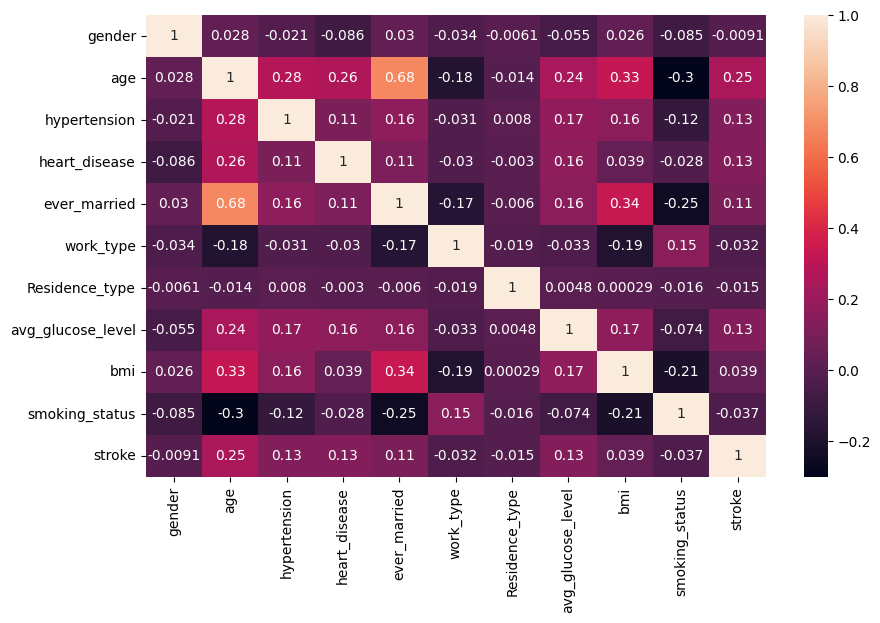

In [140]:
plt.figure(figsize=(10,6))
sns.heatmap(df.corr(),annot=True)
plt.show()

In [142]:
def plot_correlation_heatmap(df, binary_cols):
    """Plot a heatmap to visualize the correlation between numerical features."""
    plt.figure(figsize=(12, 6))
    correlation_matrix = df[numerical_cols].corr() 
    sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
    plt.title("🔹 Correlation Heatmap")
    plt.show()

In [145]:
def plot_pairplot(df, binary_cols):
    """Plot pairplot for numerical columns to observe feature relationships."""
    sns.pairplot(df[binary_cols], diag_kind="kde", corner=True)  
    plt.show()

/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  

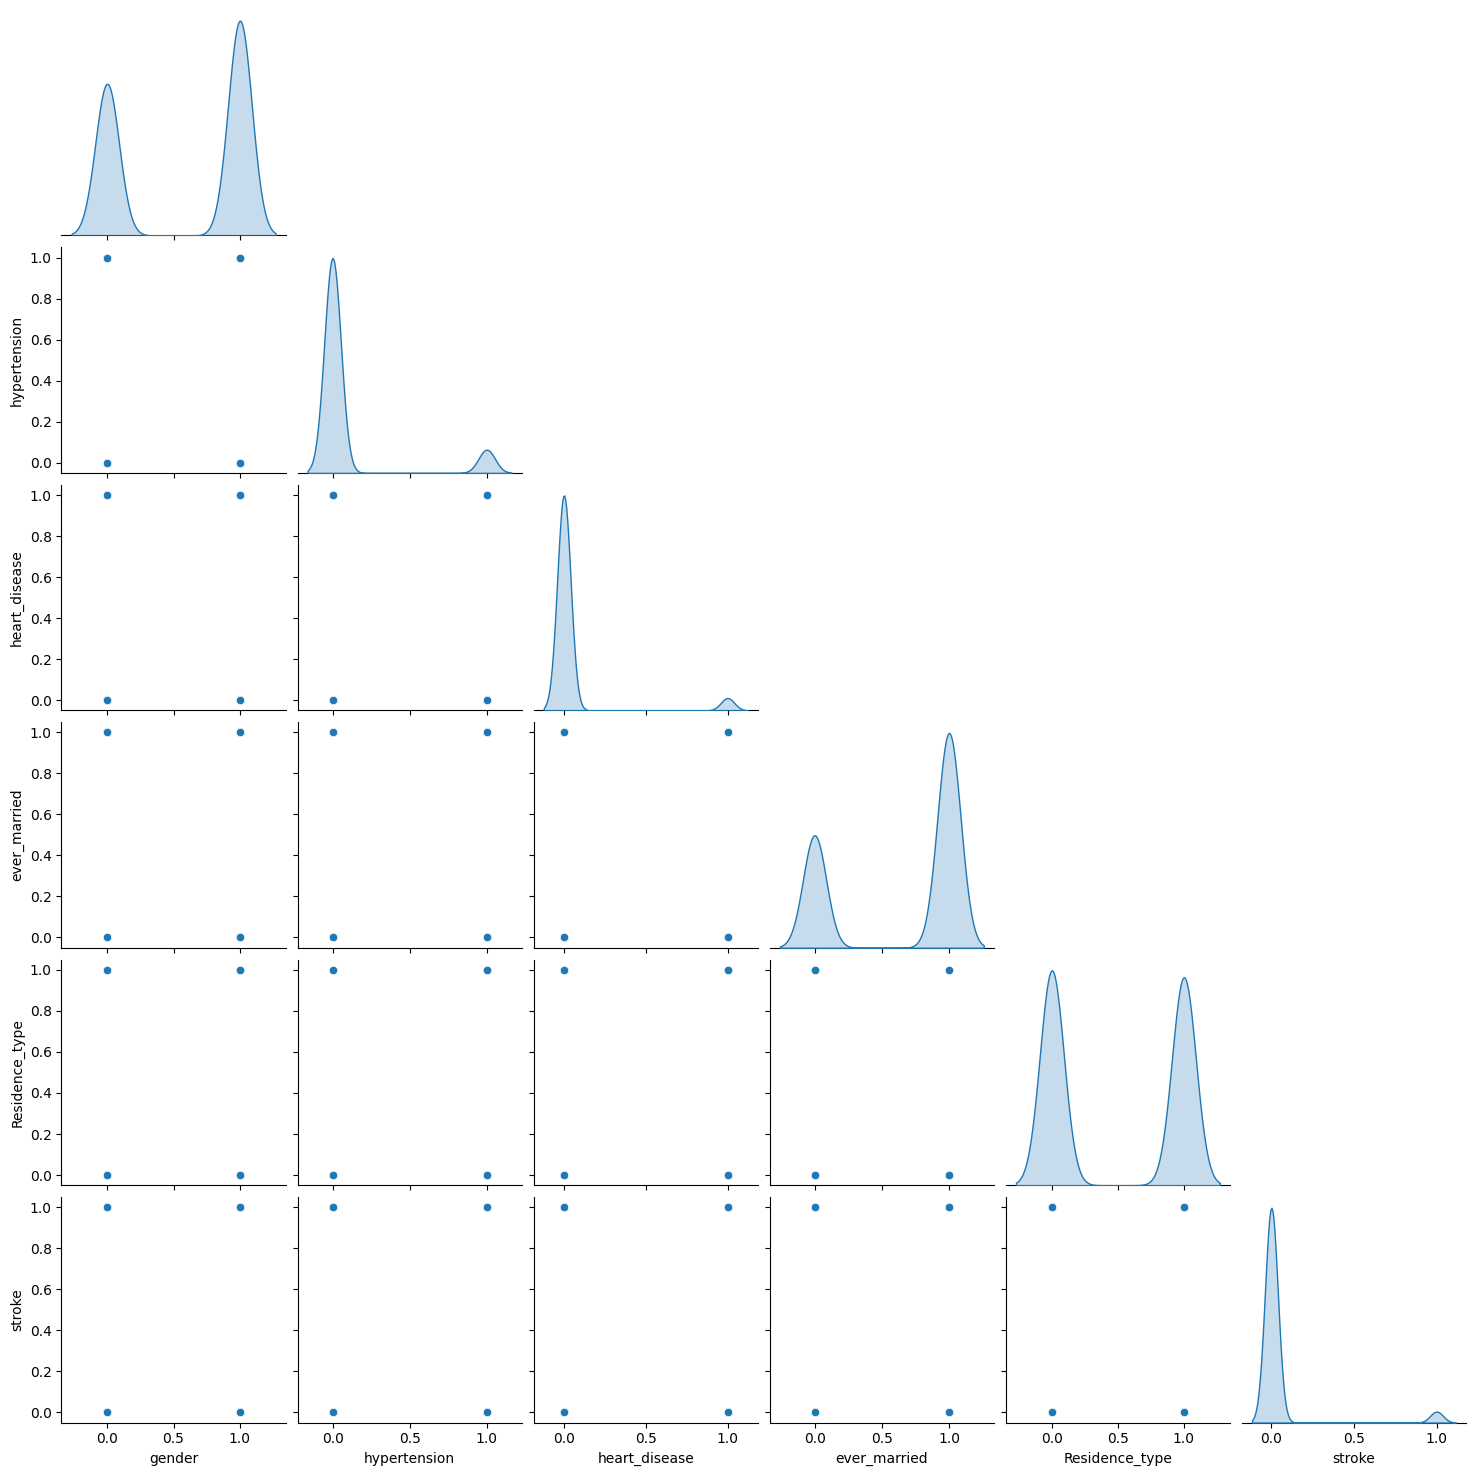

In [146]:
plot_pairplot(df, filtered_classification["binary"])

# 7. Train-Test Split & Sampling Strategy

In [148]:
X = df.drop('stroke',axis=1)
y = df.stroke
X.shape,y.shape

((5109, 10), (5109,))

In [149]:
y.value_counts()

stroke
0    4860
1     249
Name: count, dtype: int64

([<matplotlib.patches.Wedge at 0x7e7117fedc90>,
 [Text(-1.3836214247114578, 0.21352225429550808, 'No Stroke'),
  Text(1.1859612190393143, -0.18301908899014838, 'Stroke')],
 [Text(-0.8894709158859372, 0.13726430633282663, '95.1%'),
  Text(0.6918107111062667, -0.10676113524425322, '4.9%')])

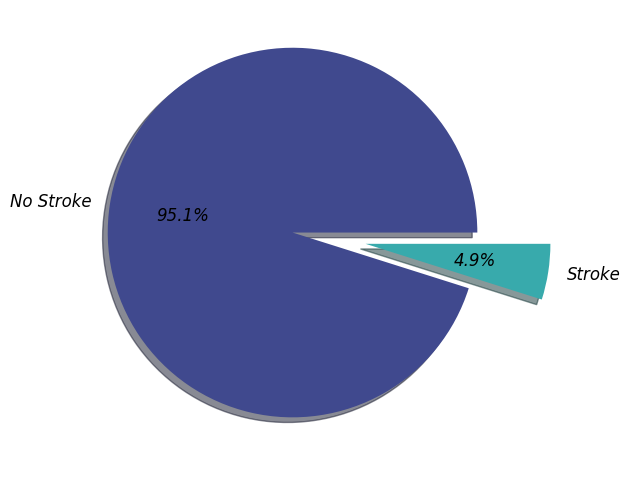

In [151]:
plt.figure(figsize=(10,6))
plt.pie(df.stroke.value_counts(),labels=['No Stroke','Stroke'],autopct='%1.1f%%',
        colors=sns.color_palette('mako',2),explode=(0.3,0.1),shadow=True,textprops={'fontsize':12,'style':'italic'})


# Balancing the target


I will use three techniques:

SMOTE
RandomOverSampler
RandomUnderSampler
✨SMOTE (Synthetic Minority Oversampling Technique): Creates synthetic data points for the minority class based on existing data points in that class. This helps increase the representation of the minority class in the training data.

✨RandomOverSampler: Randomly duplicates data points from the minority class to increase its representation. Unlike SMOTE, it doesn't create synthetic data.

✨RandomUnderSampler: Randomly removes data points from the majority class to reduce its size and match the minority class. This approach can be faster than oversampling techniques.

In [154]:
# pip show scikit-learn
!pip install -U imbalanced-learn==0.10.1

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 226.0/226.0 kB 9.1 MB/s eta 0:00:00
  Attempting uninstall: imbalanced-learn
    Found existing installation: imbalanced-learn 0.13.0
    Uninstalling imbalanced-learn-0.13.0:
      Successfully uninstalled imbalanced-learn-0.13.0


In [156]:
from imblearn.over_sampling import SMOTE,RandomOverSampler
# from imblearn.under_sampling import RandomUnderSampler
# smote = SMOTE()
# X_resampled, y_resampled = smote.fit_resample(X, y)
ros = RandomOverSampler(sampling_strategy='minority')
X_over_resampled, y_over_resampled = ros.fit_resample(X, y)
# rus = RandomUnderSampler(sampling_strategy='majority')
# X_under_resampled, y_under_resampled = rus.fit_resample(X, y)


In [157]:
# print(X_resampled.shape,y_resampled.shape)
# print(X_under_resampled.shape,y_under_resampled.shape)
print(X_over_resampled.shape,y_over_resampled.shape)

(9720, 10) (9720,)


In [158]:
# print(y_resampled.value_counts())
# print(y_under_resampled.value_counts())
print(y_over_resampled.value_counts())

stroke
1    4860
0    4860
Name: count, dtype: int64


RandomOverampler

Fitting 5 folds for each of 324 candidates, totalling 1620 fits
[CV] END max_depth=8, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=100; total time=   0.7s
[CV] END max_depth=8, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=200; total time=   1.4s
[CV] END max_depth=8, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=300; total time=   2.1s
[CV] END max_depth=8, max_features=sqrt, min_samples_leaf=1, min_samples_split=5, n_estimators=100; total time=   0.7s
[CV] END max_depth=8, max_features=sqrt, min_samples_leaf=1, min_samples_split=5, n_estimators=100; total time=   0.7s
[CV] END max_depth=8, max_features=sqrt, min_samples_leaf=1, min_samples_split=5, n_estimators=100; total time=   0.7s
[CV] END max_depth=8, max_features=sqrt, min_samples_leaf=1, min_samples_split=5, n_estimators=200; total time=   1.5s
[CV] END max_depth=8, max_features=sqrt, min_samples_leaf=1, min_samples_split=5, n_estimators=300; tot

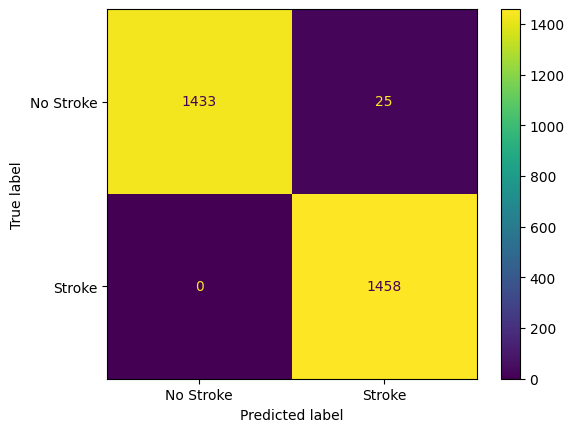

In [159]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

X_train, X_test, y_train, y_test = train_test_split(
    X_over_resampled, y_over_resampled, test_size=0.3, random_state=42
)
param_grid = {
    'n_estimators': [100, 200, 300],         # Number of trees
    'max_depth': [8, 10, 12, None],          # Maximum depth of trees
    'min_samples_split': [2, 5, 10],         # Min samples to split a node
    'min_samples_leaf': [1, 2, 5],            # Min samples per leaf
    'max_features': ['sqrt', 'log2', None]   # Number of features to consider at each split
}
rf = RandomForestClassifier(random_state=1234)

grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,                 # 5-fold cross-validation
    scoring='f1',         # Optimize for F1 score (balance of precision and recall)
    n_jobs=-1,            # Use all CPU cores
    verbose=2             # Show progress
)
grid_search.fit(X_train, y_train)
print("Best hyperparameters found:")
print(grid_search.best_params_)
best_rf = grid_search.best_estimator_
y_pred = best_rf.predict(X_test)

print(classification_report(y_test, y_pred))

ConfusionMatrixDisplay.from_estimator(best_rf, X_test, y_test, display_labels=['No Stroke', 'Stroke'])


Accuracy: 0.9914
Precision: 0.9831
Recall (Sensitivity): 1.0000
F1 Score: 0.9915
Specificity: 0.9829
TPR (Recall): 1.0000
FPR: 0.0171
CSI: 0.9831
MAE: 0.0086
MSE: 0.0086
RMSE: 0.0926


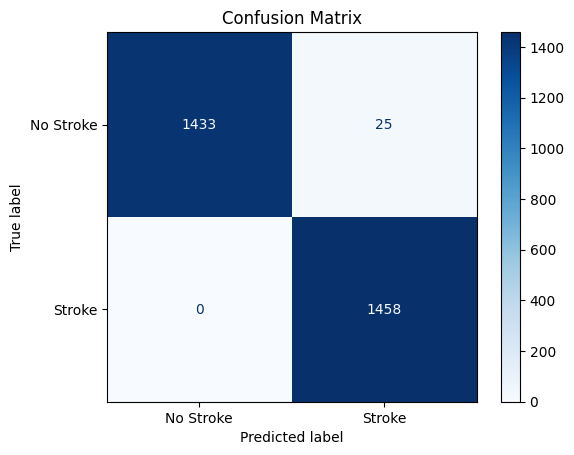

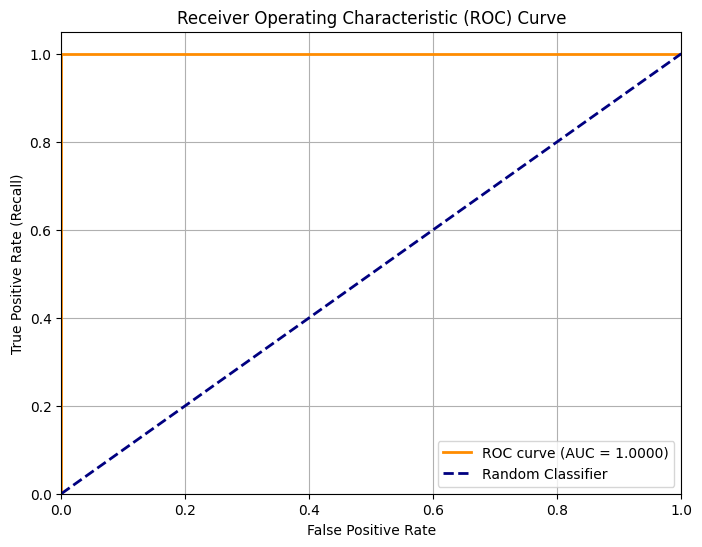


[CV] END max_depth=None, max_features=log2, min_samples_leaf=1, min_samples_split=10, n_estimators=300; total time=   2.5s
[CV] END max_depth=None, max_features=log2, min_samples_leaf=2, min_samples_split=2, n_estimators=100; total time=   0.8s
[CV] END max_depth=None, max_features=log2, min_samples_leaf=2, min_samples_split=2, n_estimators=100; total time=   0.8s
[CV] END max_depth=None, max_features=log2, min_samples_leaf=2, min_samples_split=2, n_estimators=200; total time=   1.6s
[CV] END max_depth=None, max_features=log2, min_samples_leaf=2, min_samples_split=2, n_estimators=300; total time=   2.6s
[CV] END max_depth=None, max_features=log2, min_samples_leaf=2, min_samples_split=2, n_estimators=300; total time=   3.2s
[CV] END max_depth=None, max_features=log2, min_samples_leaf=2, min_samples_split=5, n_estimators=200; total time=   1.7s
[CV] END max_depth=None, max_features=log2, min_samples_leaf=2, min_samples_split=5, n_estimators=300; total time=   2.5s
[CV] END max_depth=Non

In [160]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, mean_absolute_error, mean_squared_error
)
import numpy as np

def evaluate_model(y_true, y_pred):
    # Basic metrics
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)  # Sensitivity, same as recall
    f1 = f1_score(y_true, y_pred)

    # Confusion matrix: tn, fp, fn, tp
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

    # Specificity = tn / (tn + fp)
    specificity = tn / (tn + fp) if (tn + fp) != 0 else 0

    # True Positive Rate (TPR) = recall (same)
    tpr = recall

    # False Positive Rate (FPR) = fp / (fp + tn)
    fpr = fp / (fp + tn) if (fp + tn) != 0 else 0

    # Critical Success Index (CSI) = tp / (tp + fn + fp)
    csi = tp / (tp + fn + fp) if (tp + fn + fp) != 0 else 0

    # Regression metrics on labels (treating as numeric)
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)

    # Print all metrics
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall (Sensitivity): {recall:.4f}")
    print(f"F1 Score: {f1:.4f}")
    print(f"Specificity: {specificity:.4f}")
    print(f"TPR (Recall): {tpr:.4f}")
    print(f"FPR: {fpr:.4f}")
    print(f"CSI: {csi:.4f}")
    print(f"MAE: {mae:.4f}")
    print(f"MSE: {mse:.4f}")
    print(f"RMSE: {rmse:.4f}")

# Example usage, after prediction:
# y_pred = best_rf.predict(X_test)
evaluate_model(y_test, y_pred)

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

def plot_confusion_matrix(y_true, y_pred):
    disp = ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred, 
        display_labels=['No Stroke', 'Stroke'],
        cmap=plt.cm.Blues,
        normalize=None  # use 'true', 'pred', or None for counts
    )
    disp.ax_.set_title("Confusion Matrix")
    plt.show()

# Example usage:
plot_confusion_matrix(y_test, y_pred)
from sklearn.metrics import roc_curve, roc_auc_score

def plot_roc_curve(model, X_test, y_test):
    # Get predicted probabilities for the positive class
    y_proba = model.predict_proba(X_test)[:, 1]
    
    fpr, tpr, thresholds = roc_curve(y_test, y_proba)
    auc_score = roc_auc_score(y_test, y_proba)

    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc_score:.4f})')
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Classifier')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate (Recall)")
    plt.title("Receiver Operating Characteristic (ROC) Curve")
    plt.legend(loc="lower right")
    plt.grid(True)
    plt.show()

# Example usage:
plot_roc_curve(best_rf, X_test, y_test)


Balanced dataset shape: (9720, 10), (9720,)
Fitting 5 folds for each of 60 candidates, totalling 300 fits


/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:1165: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l1)
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:1165: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l1)
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:1165: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l1)
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:1165: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l1)
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_sag.py:

[CV] END ........C=0.01, l1_ratio=0, penalty=l1, solver=saga; total time=   2.4s
[CV] END ........C=0.01, l1_ratio=0, penalty=l2, solver=saga; total time=   2.0s
[CV] END C=0.01, l1_ratio=0, penalty=elasticnet, solver=saga; total time=   2.0s
[CV] END C=0.01, l1_ratio=0, penalty=elasticnet, solver=saga; total time=   2.0s
[CV] END ......C=0.01, l1_ratio=0, penalty=none, solver=saga; total time=   2.0s
[CV] END ......C=0.01, l1_ratio=0.5, penalty=l1, solver=saga; total time=   2.4s
[CV] END ......C=0.01, l1_ratio=0.5, penalty=l2, solver=saga; total time=   2.0s
[CV] END ......C=0.01, l1_ratio=0.5, penalty=l2, solver=saga; total time=   2.4s
[CV] END C=0.01, l1_ratio=0.5, penalty=elasticnet, solver=saga; total time=   2.7s
[CV] END ....C=0.01, l1_ratio=0.5, penalty=none, solver=saga; total time=   2.0s
[CV] END ........C=0.01, l1_ratio=1, penalty=l1, solver=saga; total time=   2.5s
[CV] END ........C=0.01, l1_ratio=1, penalty=l1, solver=saga; total time=   2.5s
[CV] END ........C=0.01, l

/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:1165: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:1165: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(


[CV] END ........C=0.01, l1_ratio=0, penalty=l1, solver=saga; total time=   2.4s
[CV] END ........C=0.01, l1_ratio=0, penalty=l2, solver=saga; total time=   1.9s
[CV] END ........C=0.01, l1_ratio=0, penalty=l2, solver=saga; total time=   2.0s
[CV] END C=0.01, l1_ratio=0, penalty=elasticnet, solver=saga; total time=   2.0s
[CV] END ......C=0.01, l1_ratio=0, penalty=none, solver=saga; total time=   1.9s
[CV] END ......C=0.01, l1_ratio=0.5, penalty=l1, solver=saga; total time=   2.3s
[CV] END ......C=0.01, l1_ratio=0.5, penalty=l2, solver=saga; total time=   1.9s
[CV] END ......C=0.01, l1_ratio=0.5, penalty=l2, solver=saga; total time=   2.5s
[CV] END C=0.01, l1_ratio=0.5, penalty=elasticnet, solver=saga; total time=   3.0s
[CV] END ....C=0.01, l1_ratio=0.5, penalty=none, solver=saga; total time=   2.0s
[CV] END ........C=0.01, l1_ratio=1, penalty=l1, solver=saga; total time=   2.4s
[CV] END ........C=0.01, l1_ratio=1, penalty=l2, solver=saga; total time=   2.0s
[CV] END ........C=0.01, l

/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:1165: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


[CV] END ........C=0.01, l1_ratio=0, penalty=l1, solver=saga; total time=   2.4s
[CV] END ........C=0.01, l1_ratio=0, penalty=l2, solver=saga; total time=   1.9s
[CV] END ........C=0.01, l1_ratio=0, penalty=l2, solver=saga; total time=   2.0s
[CV] END C=0.01, l1_ratio=0, penalty=elasticnet, solver=saga; total time=   2.0s
[CV] END ......C=0.01, l1_ratio=0, penalty=none, solver=saga; total time=   1.9s
[CV] END ......C=0.01, l1_ratio=0.5, penalty=l1, solver=saga; total time=   2.4s
[CV] END ......C=0.01, l1_ratio=0.5, penalty=l1, solver=saga; total time=   2.3s
[CV] END C=0.01, l1_ratio=0.5, penalty=elasticnet, solver=saga; total time=   3.7s
[CV] END ....C=0.01, l1_ratio=0.5, penalty=none, solver=saga; total time=   2.0s
[CV] END ....C=0.01, l1_ratio=0.5, penalty=none, solver=saga; total time=   2.0s
[CV] END ........C=0.01, l1_ratio=1, penalty=l1, solver=saga; total time=   2.4s
[CV] END ........C=0.01, l1_ratio=1, penalty=l2, solver=saga; total time=   2.1s
[CV] END C=0.01, l1_ratio=

/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:1165: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=none)
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:1173: FutureWarning: `penalty='none

Best hyperparameters: {'C': 0.01, 'l1_ratio': 0, 'penalty': 'none', 'solver': 'saga'}
Accuracy: 0.7774
Precision: 0.7539
Recall (Sensitivity): 0.8237
F1 Score: 0.7873
Specificity: 0.7311
TPR (Recall): 0.8237
FPR: 0.2689
CSI: 0.6492
MAE: 0.2226
MSE: 0.2226
RMSE: 0.4718


/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


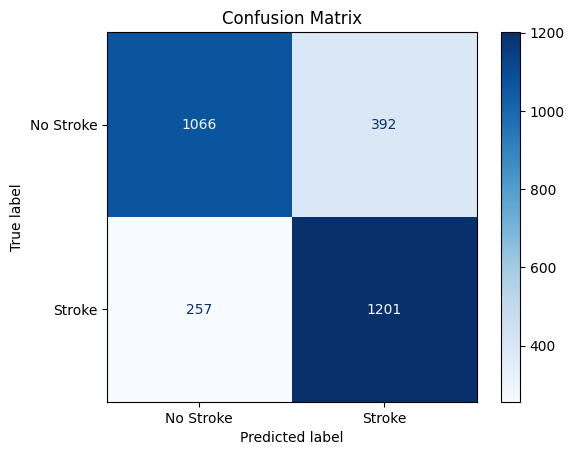

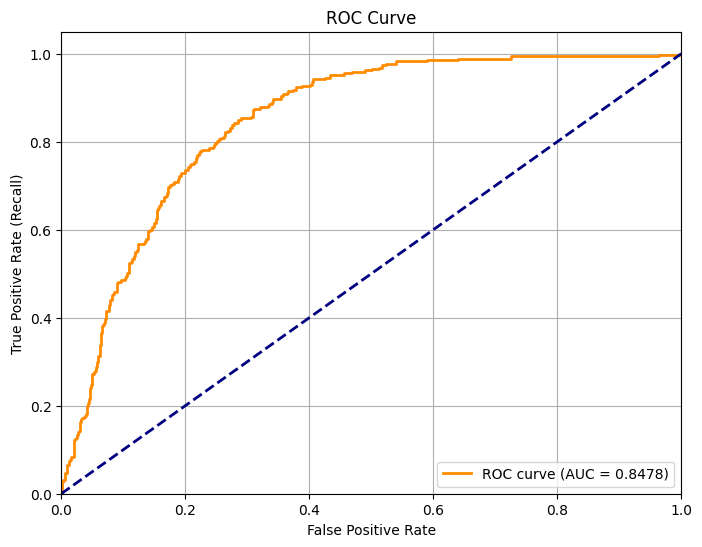

[CV] END .........C=0.1, l1_ratio=1, penalty=l2, solver=saga; total time=   1.9s
[CV] END .........C=0.1, l1_ratio=1, penalty=l2, solver=saga; total time=   1.9s
[CV] END .C=0.1, l1_ratio=1, penalty=elasticnet, solver=saga; total time=   2.4s
[CV] END .......C=0.1, l1_ratio=1, penalty=none, solver=saga; total time=   1.9s
[CV] END ...........C=1, l1_ratio=0, penalty=l1, solver=saga; total time=   2.6s
[CV] END ...........C=1, l1_ratio=0, penalty=l2, solver=saga; total time=   1.9s
[CV] END ...........C=1, l1_ratio=0, penalty=l2, solver=saga; total time=   1.9s
[CV] END ...C=1, l1_ratio=0, penalty=elasticnet, solver=saga; total time=   1.9s
[CV] END .........C=1, l1_ratio=0, penalty=none, solver=saga; total time=   1.9s
[CV] END .........C=1, l1_ratio=0.5, penalty=l1, solver=saga; total time=   3.0s
[CV] END .........C=1, l1_ratio=0.5, penalty=l1, solver=saga; total time=   2.6s
[CV] END .........C=1, l1_ratio=0.5, penalty=l2, solver=saga; total time=   2.0s
[CV] END .C=1, l1_ratio=0.5,

In [162]:
# === Step 1: Balance the dataset with ROS ===
def balance_data_ros(X, y):
    ros = RandomOverSampler(sampling_strategy='minority', random_state=42)
    X_res, y_res = ros.fit_resample(X, y)
    print(f"Balanced dataset shape: {X_res.shape}, {y_res.shape}")
    return X_res, y_res

# === Step 2: Evaluation function ===
def evaluate_model(y_true, y_pred):
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)  # Sensitivity
    f1 = f1_score(y_true, y_pred)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    specificity = tn / (tn + fp) if (tn + fp) != 0 else 0
    tpr = recall
    fpr = fp / (fp + tn) if (fp + tn) != 0 else 0
    csi = tp / (tp + fn + fp) if (tp + fn + fp) != 0 else 0
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)

    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall (Sensitivity): {recall:.4f}")
    print(f"F1 Score: {f1:.4f}")
    print(f"Specificity: {specificity:.4f}")
    print(f"TPR (Recall): {tpr:.4f}")
    print(f"FPR: {fpr:.4f}")
    print(f"CSI: {csi:.4f}")
    print(f"MAE: {mae:.4f}")
    print(f"MSE: {mse:.4f}")
    print(f"RMSE: {rmse:.4f}")

# === Step 3: Confusion matrix plot ===
def plot_confusion_matrix(y_true, y_pred):
    disp = ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred,
        display_labels=['No Stroke', 'Stroke'],
        cmap=plt.cm.Blues
    )
    disp.ax_.set_title("Confusion Matrix")
    plt.show()

# === Step 4: ROC curve plot ===
def plot_roc_curve(model, X_test, y_test):
    y_proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc_score = roc_auc_score(y_test, y_proba)

    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc_score:.4f})')
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate (Recall)")
    plt.title("ROC Curve")
    plt.legend(loc="lower right")
    plt.grid(True)
    plt.show()

# === Step 5: Main pipeline ===
def run_logistic_regression_pipeline(X, y):
    # Balance data
    X_bal, y_bal = balance_data_ros(X, y)

    # Split data
    X_train, X_test, y_train, y_test = train_test_split(
        X_bal, y_bal, test_size=0.3, random_state=42, stratify=y_bal
    )

    # Define logistic regression and param grid
    lr = LogisticRegression(max_iter=1000, random_state=1234)

    param_grid = {
        'penalty': ['l1', 'l2', 'elasticnet', 'none'],
        'C': [0.01, 0.1, 1, 10, 100],
        'solver': ['saga'],  # saga supports all penalties
        'l1_ratio': [0, 0.5, 1]  # only for elasticnet
    }

    # Grid search with 5-fold CV optimizing F1
    grid_search = GridSearchCV(
        lr, param_grid, cv=5, scoring='f1', n_jobs=-1, verbose=2, refit=True
    )

    grid_search.fit(X_train, y_train)

    print("Best hyperparameters:", grid_search.best_params_)

    best_lr = grid_search.best_estimator_

    # Predict on test
    y_pred = best_lr.predict(X_test)

    # Evaluate and plot
    evaluate_model(y_test, y_pred)
    plot_confusion_matrix(y_test, y_pred)
    plot_roc_curve(best_lr, X_test, y_test)

    return best_lr

# === Usage: pass your original dataset (X, y) ===
best_lr_model = run_logistic_regression_pipeline(X, y)